# Volume Test

Pertanyaan yang ingin dijawab notebook ini sederhana: **kalau datanya makin besar, apakah query kita masih cukup cepat?**

Untuk menjawabnya, setiap query (R1–R10 untuk read dan W1–W10 untuk write) dijalankan di tiga ukuran data:
- **small:** 10 ribu order
- **medium:** 100 ribu order
- **large:** 1 juta order

Di setiap ukuran, query dijalankan sekali untuk pemanasan, lalu lima kali lagi untuk diukur waktunya. Query dijalankan satu per satu, jadi yang kita lihat murni pengaruh ukuran data, bukan pengaruh banyaknya pengguna yang mengakses bersamaan.

Supaya pengukurannya bersih, ada dua langkah persiapan:
- **Sebelum benchmark dimulai:** database dibersihkan dengan `VACUUM (ANALYZE)`, sehingga proses perawatan otomatis PostgreSQL tidak berjalan di tengah pengukuran.
- **Sebelum setiap query:** `CHECKPOINT` dijalankan untuk menuntaskan pekerjaan tulis ke disk yang tertunda.

Kelima run kemudian dijalankan berurutan tanpa jeda, karena jeda justru membuat CPU melambat dan run berikutnya terukur lebih lama.

Analisisnya disusun dari yang detail ke yang menyeluruh:
- **Bagian 1–2:** target waktu, threshold, dan cara membaca analisis.
- **Bagian 3:** analisis setiap read (R1–R10), satu per satu.
- **Bagian 4:** analisis setiap write (W1–W10), satu per satu.
- **Bagian 5:** analisis keseluruhan yang membandingkan semua query: load test di ukuran data normal (small dan medium), stress test di ukuran data besar (large), run yang melewati threshold, query plan, standar deviasi, dan error rate.
- **Bagian 6:** kesimpulan.

Semua angka di notebook ini berasal dari hasil benchmark di `results/`.

In [1]:
import json
import math
import re
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import yaml
from IPython.display import Markdown, display
from matplotlib.ticker import FuncFormatter

pd.set_option('display.max_colwidth', None)

ROOT = Path.cwd().parent if Path.cwd().name == 'notebook' else Path.cwd()
RESULTS = ROOT / 'results'
PROFILES = ['small', 'medium', 'large']
QUERY_ORDER = [f'R{i}' for i in range(1, 11)] + [f'W{i}' for i in range(1, 11)]


def latest(pattern: str) -> Path:
    files = sorted(RESULTS.glob(pattern))
    if not files:
        raise FileNotFoundError(f'Tidak ada file {pattern} di {RESULTS}')
    return files[-1]


def category(query: str) -> str:
    if query == 'R10':
        return 'Operasional'
    return 'Transaksional' if query.startswith('W') else 'Analitik'


def plan_facts(plans: list[list[str]]) -> dict:
    # Baris Buffers pertama di setiap plan adalah total untuk statement itu.
    text = '\n'.join('\n'.join(plan) for plan in plans)
    read = temp = 0
    for plan in plans:
        for line in plan:
            match = re.search(r'Buffers: shared(?: hit=(\d+))?(?: read=(\d+))?(?:.*?temp(?: read=\d+)? written=(\d+))?',
                              line)
            if match:
                read += int(match[1] or 0) + int(match[2] or 0)
                temp += int(match[3] or 0)
                break
    return {
        'seq_scan': ', '.join(sorted(set(re.findall(r'Seq Scan on (\w+)', text)))) or '-',
        'index_scans': len(re.findall(r'Index (?:Only )?Scan', text)),
        'workers': max([int(n) for n in re.findall(r'Workers Launched: (\d+)', text)] or [0]),
        'data_read_mb': round(read * 8 / 1024, 1),
        'temp_written_mb': round(temp * 8 / 1024, 1),
    }


config = yaml.safe_load((ROOT / 'config' / 'dataset_profile.yaml').read_text())
ORDERS = {p: config['profiles'][p]['service_orders'] for p in PROFILES}

rows, meta, EXECUTIONS, TIMED_RUNS = [], [], {}, {}
for profile in PROFILES:
    path = latest(f'{profile}_*.json')
    data = json.loads(path.read_text())
    EXECUTIONS[profile] = data['warmup_runs'] + data['timed_runs']
    TIMED_RUNS[profile] = data['timed_runs']
    meta.append({
        'ukuran data': profile,
        'service orders': f'{ORDERS[profile]:,}',
        'file hasil': path.name,
        'PostgreSQL': data['postgres_version'].split()[0],
        'mulai (UTC)': data['started_at'],
        'warm-up + run': f"{data['warmup_runs']} + {data['timed_runs']}",
        'host': f"{data['host']['platform'].split('-')[0]}, {data['host']['cpu_count']} CPU",
    })
    for query in data['queries']:
        rows.append({'profile': profile, 'query': query['query'], 'title': query['title'],
                     'median_ms': query['median_ms'], 'min_ms': query['min_ms'], 'max_ms': query['max_ms'],
                     'mean_ms': query['mean_ms'], 'stdev_ms': query['stdev_ms'], 'rows': query['rows'],
                     'times_ms': query['times_ms'], 'rows_per_run': query['rows_per_run'],
                     **plan_facts(query['plans'])})

bench = pd.DataFrame(rows)
bench['category'] = bench['query'].map(category)
bench['orders'] = bench['profile'].map(ORDERS)
bench['cv_pct'] = 100 * bench['stdev_ms'] / bench['mean_ms']
bench['profile'] = pd.Categorical(bench['profile'], PROFILES, ordered=True)
bench['query'] = pd.Categorical(bench['query'], QUERY_ORDER, ordered=True)
bench = bench.sort_values(['profile', 'query']).reset_index(drop=True)

distribution = ', '.join(f'{kind} {share:.0%}' for kind, share in config['order_distribution'].items())
display(Markdown(f'**Distribusi order:** {distribution}. **Jumlah query:** {bench["query"].nunique()} per ukuran data.'))
display(pd.DataFrame(meta).set_index('ukuran data'))

**Distribusi order:** mobility 32%, food 32%, delivery 36%. **Jumlah query:** 20 per ukuran data.

,service orders,file hasil,PostgreSQL,mulai (UTC),warm-up + run,host
ukuran data,,,,,,
small,"10,000",small_20261104-162655.json,17.11,2026-11-04T09:26:48+00:00,1 + 5,"macOS, 10 CPU"
medium,"100,000",medium_20261104-162711.json,17.11,2026-11-04T09:26:57+00:00,1 + 5,"macOS, 10 CPU"
large,"1,000,000",large_20261104-162812.json,17.11,2026-11-04T09:27:13+00:00,1 + 5,"macOS, 10 CPU"


In [2]:
INK, INK_2, MUTED = '#0b0b0b', '#52514e', '#898781'
SURFACE, GRID, AXIS = '#fcfcfb', '#e1e0d9', '#c3c2b7'
BACKGROUND = '#c3c2b7'
BLUE, ORANGE = '#2a78d6', '#eb6834'

plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'figure.dpi': 110, 'font.family': 'sans-serif', 'font.size': 10,
    'text.color': INK, 'axes.labelcolor': INK_2, 'axes.titlecolor': INK,
    'axes.titlesize': 11, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.edgecolor': AXIS, 'axes.linewidth': 0.8, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.6, 'grid.linestyle': '-',
    'xtick.color': MUTED, 'ytick.color': MUTED, 'xtick.labelcolor': INK_2, 'ytick.labelcolor': INK_2,
    'legend.frameon': False, 'legend.fontsize': 9,
})
PLAIN = FuncFormatter(lambda v, _: f'{v:,.0f}' if v >= 1 else f'{v:g}')

In [3]:
def dec(value, digits=1):
    return f'{value:.{digits}f}'.replace('.', ',')


def ms_text(ms):
    if ms >= 1000:
        return dec(ms / 1000).removesuffix(',0') + ' detik'
    if ms >= 10:
        return f'{ms:,.0f}'.replace(',', '.') + ' ms'
    return dec(ms) + ' ms'


def orders_text(n):
    return dec(n / 1e6) + ' juta order'


def names(items):
    items = [str(i) for i in items]
    return items[0] if len(items) == 1 else ', '.join(items[:-1]) + ' dan ' + items[-1]


def say(text):
    display(Markdown(text))

## 1. Target waktu

Sebelum menilai cepat atau lambat, kita perlu patokan. Tidak ada standar resmi untuk ini, jadi kita pakai patokan yang umum untuk aplikasi interaktif:

| Kategori | Target | Kenapa |
|---|---|---|
| Operasional (R10) | ≤ 100 ms | Dipanggil langsung saat pengguna membuka layar. Respons di bawah 0,1 detik terasa instan. Selain itu, query database hanya sebagian dari total waktu satu request ke server, yang biasanya 200–500 ms. |
| Transaksional (W1–W10) | ≤ 200 ms | Setiap write adalah satu aksi bisnis, seperti checkout atau pembatalan, yang terdiri dari beberapa statement. Wajar kalau sedikit lebih lama dari satu pencarian. 200 ms juga masih di kisaran normal: banyak tim baru menandai query sebagai "lambat" kalau di atas 100–500 ms. |
| Analitik (R1–R9) | ≤ 2 detik | Untuk laporan atau dashboard yang dibuka sesekali. Menunggu 1–3 detik masih nyaman, tetapi di atas sekitar 10 detik orang mulai kehilangan fokus. |

Sebuah query kita anggap lulus kalau run paling lambatnya masih di bawah target. Sengaja dipakai run paling lambat, bukan median, supaya kesimpulannya tetap berlaku untuk kasus terburuk yang kita lihat.

In [4]:
SLO_MS = {'Operasional': 100, 'Transaksional': 200, 'Analitik': 2000}
bench['slo_ms'] = bench['category'].map(SLO_MS)
bench['passes'] = bench['max_ms'] <= bench['slo_ms']


def verdict_table(profiles):
    frame = bench[bench['profile'].isin(profiles)].copy()
    frame['hasil'] = [f"{worst:,.1f} ms ({'lulus' if ok else 'gagal'})" for ok, worst in zip(frame['passes'], frame['max_ms'])]
    table = frame.pivot_table(index=['category', 'query'], columns='profile', values='hasil', aggfunc='first',
                              observed=True)
    table.index.names = ['kategori', 'query']
    table.columns = [f'{p} (run terlambat)' for p in table.columns]
    passed = frame.groupby('profile', observed=True)['passes'].agg(['sum', 'count'])
    return table, ', '.join(f'{p} {int(r["sum"])}/{int(r["count"])}' for p, r in passed.iterrows())

## 2. Cara membaca analisis per query

Bagian 3 dan 4 membahas setiap query satu per satu. Semua query memakai susunan yang sama:
1. **Konteks:** kategori, target waktu, dan jumlah baris di setiap ukuran data. Untuk read, ini jumlah baris yang dikembalikan. Untuk write, ini jumlah baris yang ditambah atau diubah.
2. **Tabel:** waktu min, median, max, mean, standar deviasi (SD), dan koefisien variasi (CV) dari lima run di setiap ukuran data, ditambah jumlah run yang melewati setiap threshold. Untuk write yang terdiri dari beberapa statement, waktunya adalah total semua statement.
3. **Grafik:** kelima run di setiap ukuran data sebagai titik, median-nya sebagai garis, serta garis target dan 50% target. Sumbu tegaknya memakai skala log, karena waktunya berkisar dari kurang dari 1 ms sampai lebih dari 1 detik.
4. **Analisis:** rentang waktu, kepekaan terhadap ukuran data, standar deviasi, dan threshold.

**Kepekaan terhadap ukuran data** dilihat dari dua angka:
- **Kenaikan median:** median baru dibagi median sebelumnya, saat data naik 10 kali (small ke medium, lalu medium ke large).
- **Eksponen b:** merangkum pola pertumbuhan menjadi satu angka, lewat model waktu ∝ (jumlah order)ᵇ.
  - **Cara menghitung:** b diperoleh dari regresi linier pada skala log-log atas ke-15 run (5 run × 3 ukuran data), bukan hanya dari median.
  - **Cara membaca:** kalau b mendekati 0, waktunya hampir tidak terpengaruh ukuran data. Kalau mendekati 1, data 10 kali lebih besar membuat query 10 kali lebih lambat.
  - **Angka ± di belakangnya:** interval kepercayaan 95%, yaitu seberapa yakin kita pada nilai b. Kalau intervalnya mencakup 0, waktunya tidak terbukti bertambah. Kalau mencakup 1, pertumbuhannya tidak berbeda nyata dari linier.
  - **R²:** seberapa baik model itu menjelaskan data. Nilai mendekati 1 berarti pertumbuhannya memang mengikuti pola tersebut. Pada query yang waktunya konstan, R² wajar rendah, karena tidak ada tren yang bisa dijelaskan, hanya variasi kecil antar-run.

**Standar deviasi** menunjukkan seberapa konsisten waktunya dari run ke run:
- **SD:** rata-rata seberapa jauh setiap run meleset dari rata-ratanya, dalam milidetik.
- **CV:** SD dibagi rata-rata, dalam persen. Ini kita perlukan karena query kita ada yang 0,3 ms dan ada yang 1,5 detik, sehingga SD dalam milidetik tidak bisa dibandingkan begitu saja.

| CV | Artinya |
|---|---|
| di bawah 5% | sangat konsisten |
| 5–15% | masih wajar |
| 15% atau lebih | perlu dilihat lebih dekat |

**Threshold** yang dipakai ada tiga. Angka 50% dan 1,2 kali adalah patokan yang kita pilih sendiri, sama seperti target di bagian 1.

| Threshold | Sebuah run masuk kalau | Gunanya |
|---|---|---|
| Target | waktunya melewati target | menentukan lulus atau tidak |
| Zona waspada | waktunya 50% target atau lebih | menandai run yang masih lulus, tetapi ruangnya tinggal separuh |
| Outlier | waktunya lebih dari 1,2 kali median query itu di ukuran data yang sama | menandai run yang menyimpang dari run lainnya, terlepas dari target |

In [5]:
import numpy as np

# Regresi log-log: log10(waktu) = a + b * log10(jumlah order), memakai setiap run (bukan hanya median).
T_975 = {8: 2.306, 10: 2.228, 13: 2.160, 16: 2.120, 18: 2.101, 28: 2.048}
fits = {}
for query, group in bench.groupby('query', observed=True):
    x = np.concatenate([[math.log10(n)] * len(times) for n, times in zip(group['orders'], group['times_ms'])])
    y = np.log10(np.concatenate(list(group['times_ms'])))
    slope, intercept = np.polyfit(x, y, 1)
    residual = y - (intercept + slope * x)
    ss_res, ss_tot = (residual ** 2).sum(), ((y - y.mean()) ** 2).sum()
    df = len(x) - 2
    se = math.sqrt(ss_res / df / ((x - x.mean()) ** 2).sum())
    fits[str(query)] = {'b': slope, 'ci': T_975.get(df, 1.96) * se, 'r2': 1 - ss_res / ss_tot, 'n': len(x)}
exponent = pd.Series({q: f['b'] for q, f in fits.items()})
large = bench[bench['profile'] == 'large'].set_index('query')

# Threshold: target (bagian 1), zona waspada, dan outlier terhadap median query itu sendiri.
WARN_SHARE, OUTLIER_FACTOR = 0.5, 1.2
bench['runs'] = bench['times_ms'].map(len)
bench['over_target'] = [sum(t > slo for t in times) for times, slo in zip(bench['times_ms'], bench['slo_ms'])]
bench['over_warn'] = [sum(t >= WARN_SHARE * slo for t in times) for times, slo in zip(bench['times_ms'], bench['slo_ms'])]
bench['outliers'] = [sum(t > OUTLIER_FACTOR * median for t in times)
                     for times, median in zip(bench['times_ms'], bench['median_ms'])]
THRESHOLDS = [('run > target', 'over_target'),
              (f'run ≥ {WARN_SHARE:.0%} target', 'over_warn'),
              (f'run > {dec(OUTLIER_FACTOR)}× median', 'outliers')]
large = bench[bench['profile'] == 'large'].set_index('query')

In [6]:
PROFILE_COLORS = {'small': '#86b6ef', 'medium': '#2a78d6', 'large': '#104281'}


def idn(ms):
    # Angka milidetik dalam format Indonesia, dibulatkan dengan np.round seperti tabel.
    if ms >= 100:
        return f'{np.round(ms):,.0f}'.replace(',', '.')
    if ms >= 10:
        return f'{np.round(ms, 1):.1f}'.replace('.', ',')
    return f'{np.round(ms, 2):.2f}'.replace('.', ',')


def count_id(n):
    return f'{int(n):,}'.replace(',', '.')


def pct_id(value):
    return f'{value:.1f}%'.replace('.', ',')


def sensitivity_text(fit):
    # Aturan yang sama dengan bagian 5.4: dibaca dari interval kepercayaan 95% eksponen b.
    low, high = fit['b'] - fit['ci'], fit['b'] + fit['ci']
    if high < 0:
        return 'waktunya justru sedikit turun saat data membesar'
    if low <= 0:
        text = 'waktunya tidak terbukti bertambah saat data membesar 100 kali'
        if fit['r2'] < 0.5:
            text += '. R² yang rendah wajar di sini, karena tidak ada tren yang bisa dijelaskan, hanya variasi kecil antar-run'
        return text
    if low <= 1 <= high:
        return 'pertumbuhannya tidak berbeda nyata dari linier: data 10 kali lebih besar, waktunya juga sekitar 10 kali lebih lama'
    if high < 1:
        return 'waktunya bertambah, tetapi lebih lambat dari pertumbuhan data'
    return 'waktunya bertambah sedikit lebih cepat dari pertumbuhan data'


def run_chart(query, frame, slo):
    fig, ax = plt.subplots(figsize=(7.5, 3.2))
    for i, profile in enumerate(PROFILES):
        times = frame.loc[profile, 'times_ms']
        xs = [i + (k - (len(times) - 1) / 2) * 0.07 for k in range(len(times))]
        ax.scatter(xs, times, s=28, color=PROFILE_COLORS[profile], edgecolor=SURFACE, lw=0.8, zorder=3)
    ax.plot(range(len(PROFILES)), frame['median_ms'].values, color=INK_2, lw=1, zorder=2)
    ax.axhline(slo, color=INK_2, lw=1, zorder=1)
    ax.axhline(WARN_SHARE * slo, color=MUTED, lw=0.8, ls='--', zorder=1)
    for value, label, color in [(slo, 'target', INK_2), (WARN_SHARE * slo, f'{WARN_SHARE:.0%} target', MUTED)]:
        ax.annotate(label, (-0.45, value), xytext=(2, 3), textcoords='offset points', fontsize=8, color=color)
    ax.set_yscale('log')
    ax.minorticks_off()
    ax.yaxis.set_major_formatter(PLAIN)
    ax.set_ylim(min(min(times) for times in frame['times_ms']) / 2, slo * 2)
    ax.set_xlim(-0.5, len(PROFILES) - 0.5)
    ax.set_xticks(range(len(PROFILES)), labels=[f'{p}\n{ORDERS[p]:,} order' for p in PROFILES])
    ax.grid(axis='x', visible=False)
    ax.set_ylabel('waktu (ms, skala log)')
    ax.set_title(f'{query}: kelima run di setiap ukuran data')
    fig.tight_layout()
    plt.show()


def analyze(query):
    frame = bench[bench['query'] == query].set_index('profile').loc[PROFILES]
    slo = SLO_MS[category(query)]
    rows_label = 'Baris diubah' if query.startswith('W') else 'Baris hasil'
    say(f'**Kategori:** {category(query).lower()}. **Target:** {ms_text(slo)}. '
        f'**{rows_label} (small / medium / large):** ' + ' / '.join(count_id(n) for n in frame['rows']) + '.')

    table = pd.DataFrame({
        'min (ms)': frame['min_ms'], 'median (ms)': frame['median_ms'], 'max (ms)': frame['max_ms'],
        'mean (ms)': frame['mean_ms'], 'SD (ms)': frame['stdev_ms'], 'CV (%)': frame['cv_pct'],
    }).round(2)
    for label, key in THRESHOLDS:
        table[label] = [f'{int(n)}/{int(runs)}' for n, runs in zip(frame[key], frame['runs'])]
    table.index = pd.Index(PROFILES, name='ukuran data')
    display(table)
    run_chart(query, frame, slo)

    median, cv, fit = frame['median_ms'], frame['cv_pct'], fits[query]
    lines = ['- **Rentang waktu:** ' + ', '.join(
        f"{p} {idn(frame.loc[p, 'min_ms'])}–{idn(frame.loc[p, 'max_ms'])} ms" for p in PROFILES) + '.']

    lines.append(f"- **Kepekaan terhadap ukuran data:** setiap kali data naik 10 kali, median-nya menjadi "
                 f"{dec(median['medium'] / median['small'])} kali semula (small ke medium) dan "
                 f"{dec(median['large'] / median['medium'])} kali semula (medium ke large). Eksponen b = "
                 f"{dec(fit['b'], 2)} ± {dec(fit['ci'], 2)} (R² {dec(fit['r2'], 2)}), artinya {sensitivity_text(fit)}.")

    if (cv < 5).all():
        verdict = 'Ketiganya di bawah 5%, jadi waktunya sangat konsisten.'
    elif (cv < 15).all():
        verdict = 'Ketiganya di bawah 15%, jadi variasinya masih wajar.'
    else:
        high = [p for p in PROFILES if cv[p] >= 15]
        verdict = (f'CV di {names(high)} 15% atau lebih. Dalam milidetik, selisih run terlambat dengan median-nya '
                   + names(f"{idn(frame.loc[p, 'max_ms'] - median[p])} ms di {p}" for p in high) + '.')
    lines.append(f"- **Standar deviasi:** SD {' / '.join(idn(s) for s in frame['stdev_ms'])} ms, atau CV "
                 f"{' / '.join(pct_id(c) for c in cv)} (small / medium / large). {verdict}")

    total = int(frame['runs'].sum())
    warn_where = [f"{int(frame.loc[p, 'over_warn'])} di {p}" for p in PROFILES if frame.loc[p, 'over_warn'] > 0]
    outliers = [f'run ke-{k} di {p} ({idn(t)} ms, median {idn(median[p])} ms)'
                for p in PROFILES for k, t in enumerate(frame.loc[p, 'times_ms'], 1) if t > OUTLIER_FACTOR * median[p]]
    lines.append(f"- **Threshold:** {int(frame['over_target'].sum())} dari {total} run melewati target. "
                 f"{int(frame['over_warn'].sum())} dari {total} run ada di zona waspada (≥ {WARN_SHARE:.0%} target)"
                 + (f': {names(warn_where)}.' if warn_where else '.')
                 + f" {int(frame['outliers'].sum())} dari {total} run termasuk outlier (lebih dari "
                 f"{dec(OUTLIER_FACTOR)} kali median)" + (f': {names(outliers)}.' if outliers else '.'))
    say('\n'.join(lines))

## 3. Analisis per query: read (R1–R10)

Setiap sub-bagian membahas satu read dengan susunan dari bagian 2.

### R1: Driver Performance & Acceptance Rate Analysis

**Maksud query:** mengukur seberapa sering setiap driver menerima tawaran trip. Acceptance rate dihitung dari jumlah tawaran yang diterima dibagi jumlah tawaran yang diterima atau ditolak. Tawaran yang kedaluwarsa (EXPIRED) ditampilkan terpisah dan tidak ikut dihitung. Hanya driver dengan minimal 5 tawaran yang diterima atau ditolak yang ditampilkan.

**Yang bisa didapat:** daftar driver, diurutkan dari acceptance rate tertinggi, lengkap dengan jumlah tawaran yang diterima, ditolak, dan kedaluwarsa. Dari sini terlihat driver mana yang paling sering menerima order, dan mana yang sering menolak.

**Kategori:** analitik. **Target:** 2 detik. **Baris hasil (small / medium / large):** 497 / 4.984 / 49.862.

,min (ms),median (ms),max (ms),mean (ms),SD (ms),CV (%),run > target,run ≥ 50% target,"run > 1,2× median"
ukuran data,,,,,,,,,
small,6.76,6.95,7.06,6.94,0.12,1.66,0/5,0/5,0/5
medium,47.39,53.51,60.79,53.64,5.42,10.11,0/5,0/5,0/5
large,576.14,605.87,793.97,638.62,88.53,13.86,0/5,0/5,1/5


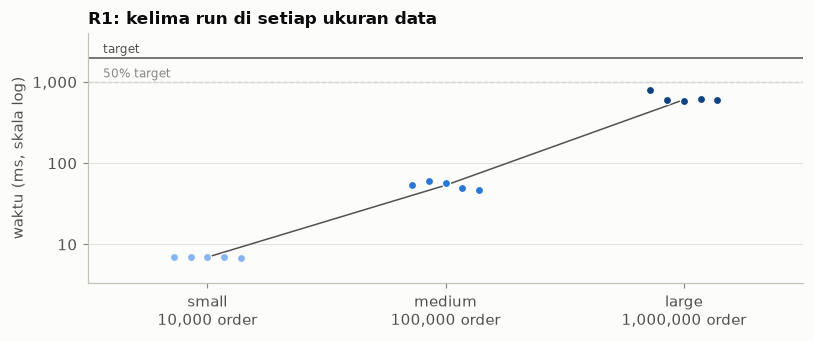

- **Rentang waktu:** small 6,76–7,06 ms, medium 47,4–60,8 ms, large 576–794 ms.
- **Kepekaan terhadap ukuran data:** setiap kali data naik 10 kali, median-nya menjadi 7,7 kali semula (small ke medium) dan 11,3 kali semula (medium ke large). Eksponen b = 0,98 ± 0,04 (R² 0,99), artinya pertumbuhannya tidak berbeda nyata dari linier: data 10 kali lebih besar, waktunya juga sekitar 10 kali lebih lama.
- **Standar deviasi:** SD 0,12 / 5,42 / 88,5 ms, atau CV 1,7% / 10,1% / 13,9% (small / medium / large). Ketiganya di bawah 15%, jadi variasinya masih wajar.
- **Threshold:** 0 dari 15 run melewati target. 0 dari 15 run ada di zona waspada (≥ 50% target). 1 dari 15 run termasuk outlier (lebih dari 1,2 kali median): run ke-1 di large (794 ms, median 606 ms).

In [7]:
analyze('R1')

### R2: Top 10 Drivers by Cumulative Trip Duration & Completed Trips

**Maksud query:** mencari 10 driver dengan total durasi perjalanan terlama. Durasi dihitung dari trip berstatus COMPLETED (`completed_at` dikurangi `started_at`) yang assignment-nya diterima oleh driver tersebut.

**Yang bisa didapat:** 10 driver teratas beserta jumlah trip yang diselesaikan, total durasi, dan rata-rata durasi per trip, dalam menit. Dari sini terlihat driver yang paling banyak menghabiskan waktu untuk mengantar.

**Kategori:** analitik. **Target:** 2 detik. **Baris hasil (small / medium / large):** 10 / 10 / 10.

,min (ms),median (ms),max (ms),mean (ms),SD (ms),CV (%),run > target,run ≥ 50% target,"run > 1,2× median"
ukuran data,,,,,,,,,
small,7.90,7.94,10.92,8.62,1.31,15.15,0/5,0/5,1/5
medium,63.08,73.49,80.74,71.50,6.89,9.63,0/5,0/5,0/5
large,1030.04,1041.01,1240.89,1078.98,90.93,8.43,0/5,5/5,0/5


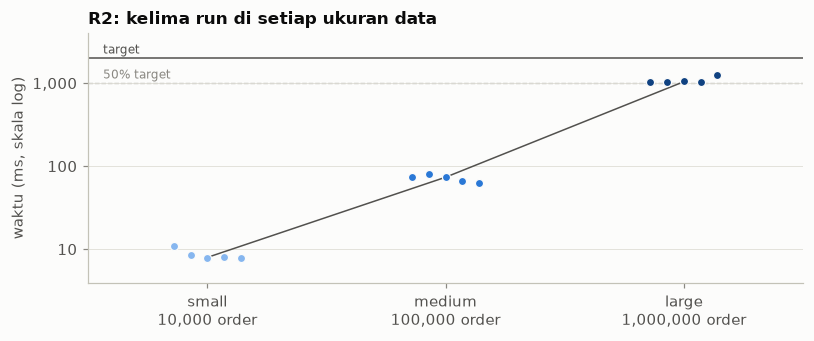

- **Rentang waktu:** small 7,90–10,9 ms, medium 63,1–80,7 ms, large 1.030–1.241 ms.
- **Kepekaan terhadap ukuran data:** setiap kali data naik 10 kali, median-nya menjadi 9,3 kali semula (small ke medium) dan 14,2 kali semula (medium ke large). Eksponen b = 1,05 ± 0,05 (R² 0,99), artinya pertumbuhannya tidak berbeda nyata dari linier: data 10 kali lebih besar, waktunya juga sekitar 10 kali lebih lama.
- **Standar deviasi:** SD 1,31 / 6,89 / 90,9 ms, atau CV 15,1% / 9,6% / 8,4% (small / medium / large). CV di small 15% atau lebih. Dalam milidetik, selisih run terlambat dengan median-nya 2,99 ms di small.
- **Threshold:** 0 dari 15 run melewati target. 5 dari 15 run ada di zona waspada (≥ 50% target): 5 di large. 1 dari 15 run termasuk outlier (lebih dari 1,2 kali median): run ke-1 di small (10,9 ms, median 7,94 ms).

In [8]:
analyze('R2')

### R3: Vehicle Type Utilization across Hourly Peak Times

**Maksud query:** melihat pemakaian setiap jenis kendaraan di setiap jam dalam sehari. Yang dihitung hanya trip yang sedang berjalan (IN_PROGRESS) atau sudah selesai (COMPLETED), dari assignment yang diterima driver.

**Yang bisa didapat:** jumlah trip dan jumlah kendaraan unik untuk setiap pasangan jenis kendaraan dan jam mulai trip. Dari sini terlihat jam sibuk untuk setiap jenis kendaraan, dan berapa kendaraan yang beroperasi di jam itu.

**Kategori:** analitik. **Target:** 2 detik. **Baris hasil (small / medium / large):** 144 / 144 / 144.

,min (ms),median (ms),max (ms),mean (ms),SD (ms),CV (%),run > target,run ≥ 50% target,"run > 1,2× median"
ukuran data,,,,,,,,,
small,19.95,20.38,20.84,20.43,0.37,1.80,0/5,0/5,0/5
medium,264.80,271.42,289.97,275.98,10.74,3.89,0/5,0/5,0/5
large,1501.37,1553.20,1626.19,1551.24,52.33,3.37,0/5,5/5,0/5


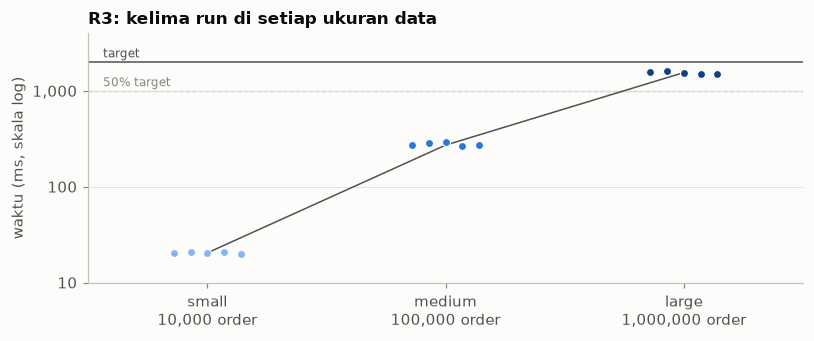

- **Rentang waktu:** small 20,0–20,8 ms, medium 265–290 ms, large 1.501–1.626 ms.
- **Kepekaan terhadap ukuran data:** setiap kali data naik 10 kali, median-nya menjadi 13,3 kali semula (small ke medium) dan 5,7 kali semula (medium ke large). Eksponen b = 0,94 ± 0,07 (R² 0,99), artinya pertumbuhannya tidak berbeda nyata dari linier: data 10 kali lebih besar, waktunya juga sekitar 10 kali lebih lama.
- **Standar deviasi:** SD 0,37 / 10,7 / 52,3 ms, atau CV 1,8% / 3,9% / 3,4% (small / medium / large). Ketiganya di bawah 5%, jadi waktunya sangat konsisten.
- **Threshold:** 0 dari 15 run melewati target. 5 dari 15 run ada di zona waspada (≥ 50% target): 5 di large. 0 dari 15 run termasuk outlier (lebih dari 1,2 kali median).

In [9]:
analyze('R3')

### R4: Re-assignment History Analysis (High Allocation Churn Trips)

**Maksud query:** mengidentifikasi trip dengan tingkat alokasi tinggi (>2 kali penugasan driver) yang pada akhirnya berhasil diselesaikan.

**Yang bisa didapat:** daftar trip beserta order-nya, status trip, jumlah tawaran, serta waktu mulai dan selesai, diurutkan dari jumlah tawaran terbanyak. Dari sini terlihat trip mana yang paling sulit mendapatkan driver.

**Kategori:** analitik. **Target:** 2 detik. **Baris hasil (small / medium / large):** 1.359 / 13.083 / 129.895.

,min (ms),median (ms),max (ms),mean (ms),SD (ms),CV (%),run > target,run ≥ 50% target,"run > 1,2× median"
ukuran data,,,,,,,,,
small,6.01,6.12,6.29,6.13,0.10,1.71,0/5,0/5,0/5
medium,60.19,63.01,72.87,64.68,4.90,7.58,0/5,0/5,0/5
large,588.22,603.87,620.24,604.89,13.47,2.23,0/5,0/5,0/5


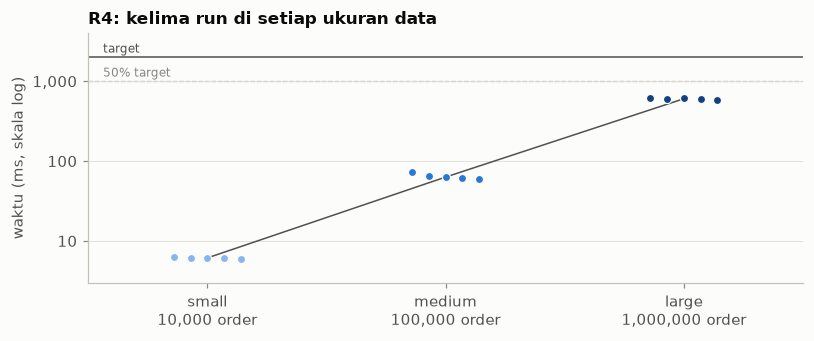

- **Rentang waktu:** small 6,01–6,29 ms, medium 60,2–72,9 ms, large 588–620 ms.
- **Kepekaan terhadap ukuran data:** setiap kali data naik 10 kali, median-nya menjadi 10,3 kali semula (small ke medium) dan 9,6 kali semula (medium ke large). Eksponen b = 1,00 ± 0,02 (R² 1,00), artinya pertumbuhannya tidak berbeda nyata dari linier: data 10 kali lebih besar, waktunya juga sekitar 10 kali lebih lama.
- **Standar deviasi:** SD 0,10 / 4,90 / 13,5 ms, atau CV 1,7% / 7,6% / 2,2% (small / medium / large). Ketiganya di bawah 15%, jadi variasinya masih wajar.
- **Threshold:** 0 dari 15 run melewati target. 0 dari 15 run ada di zona waspada (≥ 50% target). 0 dari 15 run termasuk outlier (lebih dari 1,2 kali median).

In [10]:
analyze('R4')

### R5: Total Trips per Service Area

**Maksud query:** menghitung berapa banyak trip yang dimulai dari setiap service area, berdasarkan lokasi awal trip. Service area yang belum punya trip tidak ditampilkan.

**Yang bisa didapat:** jumlah trip per service area, diurutkan dari yang terbanyak. Dari sini terlihat area dengan permintaan perjalanan tertinggi, sebagai dasar pemetaan permintaan operasional.

**Kategori:** analitik. **Target:** 2 detik. **Baris hasil (small / medium / large):** 23 / 23 / 23.

,min (ms),median (ms),max (ms),mean (ms),SD (ms),CV (%),run > target,run ≥ 50% target,"run > 1,2× median"
ukuran data,,,,,,,,,
small,3.40,3.49,3.75,3.53,0.14,4.05,0/5,0/5,0/5
medium,33.66,35.82,37.78,35.90,1.80,5.01,0/5,0/5,0/5
large,143.83,149.43,154.25,149.02,4.95,3.32,0/5,0/5,0/5


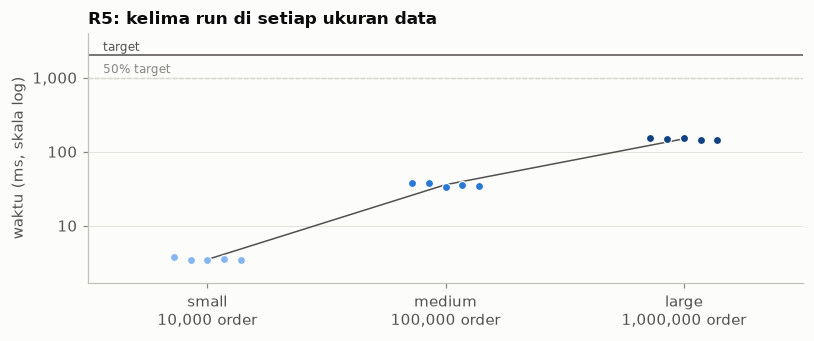

- **Rentang waktu:** small 3,40–3,75 ms, medium 33,7–37,8 ms, large 144–154 ms.
- **Kepekaan terhadap ukuran data:** setiap kali data naik 10 kali, median-nya menjadi 10,3 kali semula (small ke medium) dan 4,2 kali semula (medium ke large). Eksponen b = 0,81 ± 0,07 (R² 0,98), artinya waktunya bertambah, tetapi lebih lambat dari pertumbuhan data.
- **Standar deviasi:** SD 0,14 / 1,80 / 4,95 ms, atau CV 4,0% / 5,0% / 3,3% (small / medium / large). Ketiganya di bawah 15%, jadi variasinya masih wajar.
- **Threshold:** 0 dari 15 run melewati target. 0 dari 15 run ada di zona waspada (≥ 50% target). 0 dari 15 run termasuk outlier (lebih dari 1,2 kali median).

In [11]:
analyze('R5')

### R6: Revenue and Refunds per Service Area

**Maksud query:** menghitung pendapatan dan refund setiap service area. Yang dihitung hanya payment yang sudah selesai, yaitu PAID atau REFUNDED. Area sebuah order diambil dari lokasi awal trip-nya. Kalau satu order punya lebih dari satu trip, hanya trip dengan ID terkecil yang dipakai (CTE `first_trip`), supaya pembayarannya tidak terhitung dua kali. Order yang tidak punya trip tidak ikut dihitung.

**Yang bisa didapat:** untuk setiap service area: jumlah payment yang sudah selesai, pendapatan bersih (payment PAID), total refund, dan persentase refund, diurutkan dari pendapatan bersih tertinggi. Dari sini terlihat area yang paling banyak menghasilkan pendapatan, dan area yang tingkat refund-nya tinggi.

**Kategori:** analitik. **Target:** 2 detik. **Baris hasil (small / medium / large):** 23 / 23 / 23.

,min (ms),median (ms),max (ms),mean (ms),SD (ms),CV (%),run > target,run ≥ 50% target,"run > 1,2× median"
ukuran data,,,,,,,,,
small,10.04,10.22,10.38,10.21,0.13,1.29,0/5,0/5,0/5
medium,107.98,121.65,142.04,122.95,13.59,11.05,0/5,0/5,0/5
large,834.46,849.36,867.42,853.40,13.81,1.62,0/5,0/5,0/5


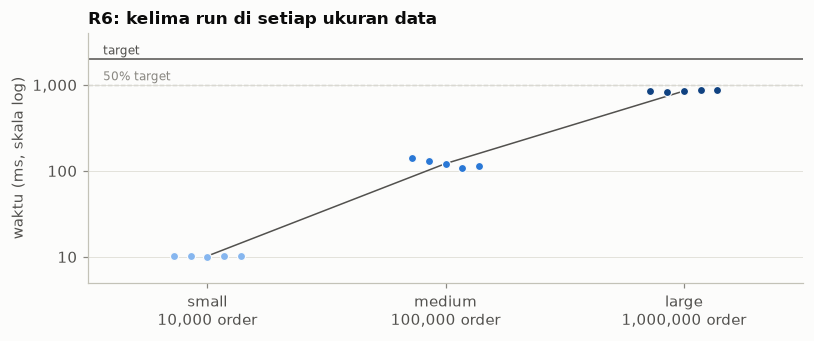

- **Rentang waktu:** small 10,0–10,4 ms, medium 108–142 ms, large 834–867 ms.
- **Kepekaan terhadap ukuran data:** setiap kali data naik 10 kali, median-nya menjadi 11,9 kali semula (small ke medium) dan 7,0 kali semula (medium ke large). Eksponen b = 0,96 ± 0,04 (R² 0,99), artinya pertumbuhannya tidak berbeda nyata dari linier: data 10 kali lebih besar, waktunya juga sekitar 10 kali lebih lama.
- **Standar deviasi:** SD 0,13 / 13,6 / 13,8 ms, atau CV 1,3% / 11,1% / 1,6% (small / medium / large). Ketiganya di bawah 15%, jadi variasinya masih wajar.
- **Threshold:** 0 dari 15 run melewati target. 0 dari 15 run ada di zona waspada (≥ 50% target). 0 dari 15 run termasuk outlier (lebih dari 1,2 kali median).

In [12]:
analyze('R6')

### R7: Monthly Payment Summary per Payment Method

**Maksud query:** merangkum pembayaran per bulan dan per metode pembayaran. Bulan diambil dari waktu order dibuat (UTC).

**Yang bisa didapat:** untuk setiap bulan dan metode pembayaran: jumlah payment per status (PAID, REFUNDED, FAILED, PENDING), persentase payment yang berhasil dibayar dari payment yang sudah selesai (bukan PENDING), pendapatan bersih, dan rata-rata waktu dari order dibuat sampai dibayar, dalam menit. Untuk CASH, status FAILED berarti order dibatalkan sebelum dibayar, bukan pembayaran yang ditolak.

**Kategori:** analitik. **Target:** 2 detik. **Baris hasil (small / medium / large):** 24 / 25 / 27.

,min (ms),median (ms),max (ms),mean (ms),SD (ms),CV (%),run > target,run ≥ 50% target,"run > 1,2× median"
ukuran data,,,,,,,,,
small,6.67,6.76,7.07,6.83,0.17,2.49,0/5,0/5,0/5
medium,82.36,85.99,102.60,88.31,8.13,9.21,0/5,0/5,0/5
large,518.53,531.24,538.20,530.48,7.79,1.47,0/5,0/5,0/5


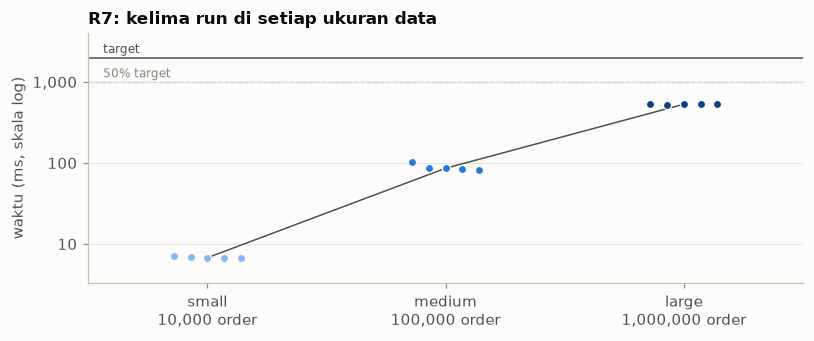

- **Rentang waktu:** small 6,67–7,07 ms, medium 82,4–103 ms, large 519–538 ms.
- **Kepekaan terhadap ukuran data:** setiap kali data naik 10 kali, median-nya menjadi 12,7 kali semula (small ke medium) dan 6,2 kali semula (medium ke large). Eksponen b = 0,95 ± 0,06 (R² 0,99), artinya pertumbuhannya tidak berbeda nyata dari linier: data 10 kali lebih besar, waktunya juga sekitar 10 kali lebih lama.
- **Standar deviasi:** SD 0,17 / 8,13 / 7,79 ms, atau CV 2,5% / 9,2% / 1,5% (small / medium / large). Ketiganya di bawah 15%, jadi variasinya masih wajar.
- **Threshold:** 0 dari 15 run melewati target. 0 dari 15 run ada di zona waspada (≥ 50% target). 0 dari 15 run termasuk outlier (lebih dari 1,2 kali median).

In [13]:
analyze('R7')

### R8: Top 10 Merchant Outlets by Food Revenue

**Maksud query:** mencari 10 merchant outlet dengan pendapatan bersih tertinggi dari food order yang sudah selesai (COMPLETED).

**Yang bisa didapat:** untuk setiap outlet: status outlet, kota dan area, jumlah order yang selesai, pendapatan bersih, rata-rata nilai order, dan persentase refund. Dari sini terlihat outlet yang paling banyak menghasilkan pendapatan.

**Kategori:** analitik. **Target:** 2 detik. **Baris hasil (small / medium / large):** 10 / 10 / 10.

,min (ms),median (ms),max (ms),mean (ms),SD (ms),CV (%),run > target,run ≥ 50% target,"run > 1,2× median"
ukuran data,,,,,,,,,
small,6.02,6.15,6.58,6.24,0.25,4.00,0/5,0/5,0/5
medium,98.10,100.08,116.88,102.71,7.99,7.78,0/5,0/5,0/5
large,563.76,584.22,594.56,580.46,13.84,2.38,0/5,0/5,0/5


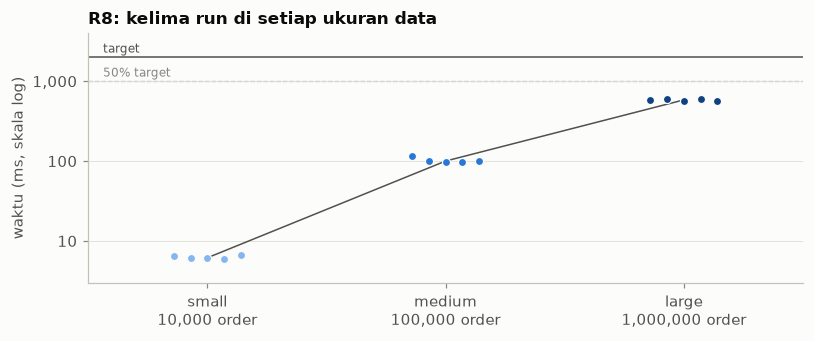

- **Rentang waktu:** small 6,02–6,58 ms, medium 98,1–117 ms, large 564–595 ms.
- **Kepekaan terhadap ukuran data:** setiap kali data naik 10 kali, median-nya menjadi 16,3 kali semula (small ke medium) dan 5,8 kali semula (medium ke large). Eksponen b = 0,98 ± 0,08 (R² 0,98), artinya pertumbuhannya tidak berbeda nyata dari linier: data 10 kali lebih besar, waktunya juga sekitar 10 kali lebih lama.
- **Standar deviasi:** SD 0,25 / 7,99 / 13,8 ms, atau CV 4,0% / 7,8% / 2,4% (small / medium / large). Ketiganya di bawah 15%, jadi variasinya masih wajar.
- **Threshold:** 0 dari 15 run melewati target. 0 dari 15 run ada di zona waspada (≥ 50% target). 0 dari 15 run termasuk outlier (lebih dari 1,2 kali median).

In [14]:
analyze('R8')

### R9: Outlet Supply vs Food Demand per Service Area (October 2026)

**Maksud query:** membandingkan pasokan outlet dengan permintaan food order di setiap service area pada Oktober 2026, bulan terakhir di dataset. Outlet dan order dihitung terpisah lalu digabung dengan LEFT JOIN, sehingga area tanpa outlet atau tanpa order tetap ditampilkan.

**Yang bisa didapat:** untuk setiap service area: jumlah outlet, jumlah outlet yang OPEN, jumlah food order bulan itu, dan rata-rata order per outlet OPEN. Area dengan rata-rata tertinggi adalah area yang paling kekurangan outlet.

**Kategori:** analitik. **Target:** 2 detik. **Baris hasil (small / medium / large):** 23 / 23 / 23.

,min (ms),median (ms),max (ms),mean (ms),SD (ms),CV (%),run > target,run ≥ 50% target,"run > 1,2× median"
ukuran data,,,,,,,,,
small,1.81,1.94,1.99,1.90,0.08,4.21,0/5,0/5,0/5
medium,13.61,14.00,15.14,14.15,0.60,4.26,0/5,0/5,0/5
large,97.36,103.32,106.91,102.63,3.47,3.38,0/5,0/5,0/5


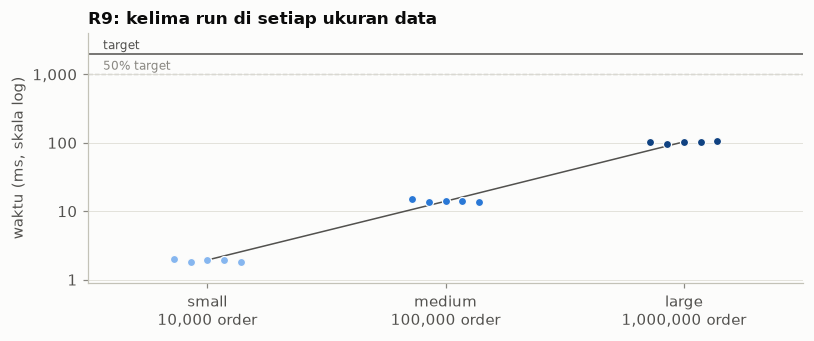

- **Rentang waktu:** small 1,81–1,99 ms, medium 13,6–15,1 ms, large 97,4–107 ms.
- **Kepekaan terhadap ukuran data:** setiap kali data naik 10 kali, median-nya menjadi 7,2 kali semula (small ke medium) dan 7,4 kali semula (medium ke large). Eksponen b = 0,87 ± 0,01 (R² 1,00), artinya waktunya bertambah, tetapi lebih lambat dari pertumbuhan data.
- **Standar deviasi:** SD 0,08 / 0,60 / 3,47 ms, atau CV 4,2% / 4,3% / 3,4% (small / medium / large). Ketiganya di bawah 5%, jadi waktunya sangat konsisten.
- **Threshold:** 0 dari 15 run melewati target. 0 dari 15 run ada di zona waspada (≥ 50% target). 0 dari 15 run termasuk outlier (lebih dari 1,2 kali median).

In [15]:
analyze('R9')

### R10: Open Merchant Outlets in a Service Area (Operational Query)

**Maksud query:** query operasional yang meniru permintaan aplikasi saat customer di Tebet, Jakarta membuka menu pesan makanan. Query ini mengambil halaman pertama (20 outlet) dari daftar outlet OPEN di service area yang aktif. Berbeda dengan R1–R9 yang merangkum data, query ini hanya membaca baris untuk satu permintaan pengguna, dan dijalankan sangat sering.

**Yang bisa didapat:** nama outlet, alamat, dan koordinatnya, diurutkan berdasarkan nama outlet, siap ditampilkan di aplikasi.

**Kategori:** operasional. **Target:** 100 ms. **Baris hasil (small / medium / large):** 10 / 20 / 20.

,min (ms),median (ms),max (ms),mean (ms),SD (ms),CV (%),run > target,run ≥ 50% target,"run > 1,2× median"
ukuran data,,,,,,,,,
small,0.32,0.35,0.48,0.38,0.06,16.71,0/5,0/5,1/5
medium,0.87,0.93,0.97,0.92,0.05,5.10,0/5,0/5,0/5
large,5.88,6.22,7.28,6.54,0.65,9.92,0/5,0/5,0/5


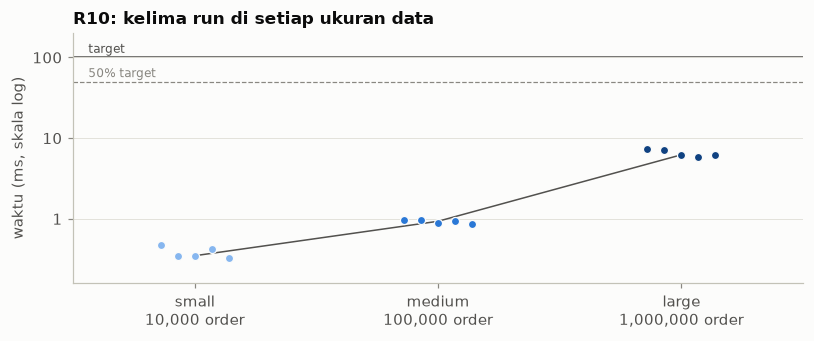

- **Rentang waktu:** small 0,32–0,48 ms, medium 0,87–0,97 ms, large 5,88–7,28 ms.
- **Kepekaan terhadap ukuran data:** setiap kali data naik 10 kali, median-nya menjadi 2,7 kali semula (small ke medium) dan 6,7 kali semula (medium ke large). Eksponen b = 0,62 ± 0,09 (R² 0,95), artinya waktunya bertambah, tetapi lebih lambat dari pertumbuhan data.
- **Standar deviasi:** SD 0,06 / 0,05 / 0,65 ms, atau CV 16,7% / 5,1% / 9,9% (small / medium / large). CV di small 15% atau lebih. Dalam milidetik, selisih run terlambat dengan median-nya 0,13 ms di small.
- **Threshold:** 0 dari 15 run melewati target. 0 dari 15 run ada di zona waspada (≥ 50% target). 1 dari 15 run termasuk outlier (lebih dari 1,2 kali median): run ke-1 di small (0,48 ms, median 0,35 ms).

In [16]:
analyze('R10')

## 4. Analisis per query: write (W1–W10)

Susunannya sama dengan bagian 3. Kolom baris berisi jumlah baris yang ditambah atau diubah, dan waktunya adalah total semua statement di write itu.

### W1: Create New Trip Record upon Order Confirmation

**Maksud query:** membuat trip baru berstatus SEARCHING untuk order CONFIRMED yang belum punya trip. Data generator tidak punya order seperti itu, sehingga dalam transaksi yang sama dibuat lebih dulu order cash baru ORD9999001 yang langsung CONFIRMED, beserta mobility order dan payment CASH yang masih PENDING.

**Yang bisa didapat:** satu order baru dan satu trip TRP9999001 yang mulai mencari driver. Trip ini dipakai oleh W2, W3, dan W5.

**Kategori:** transaksional. **Target:** 200 ms. **Baris diubah (small / medium / large):** 4 / 4 / 4.

,min (ms),median (ms),max (ms),mean (ms),SD (ms),CV (%),run > target,run ≥ 50% target,"run > 1,2× median"
ukuran data,,,,,,,,,
small,4.14,4.50,7.09,4.92,1.23,25.07,0/5,0/5,1/5
medium,4.81,7.28,9.94,6.92,2.04,29.47,0/5,0/5,1/5
large,16.98,19.61,20.58,18.99,1.74,9.19,0/5,0/5,0/5


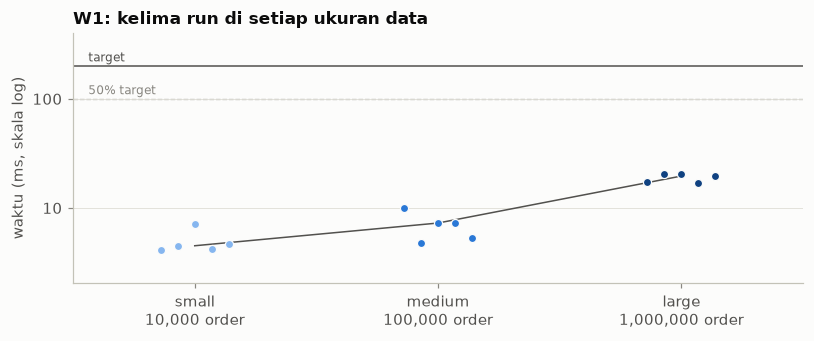

- **Rentang waktu:** small 4,14–7,09 ms, medium 4,81–9,94 ms, large 17,0–20,6 ms.
- **Kepekaan terhadap ukuran data:** setiap kali data naik 10 kali, median-nya menjadi 1,6 kali semula (small ke medium) dan 2,7 kali semula (medium ke large). Eksponen b = 0,30 ± 0,08 (R² 0,82), artinya waktunya bertambah, tetapi lebih lambat dari pertumbuhan data.
- **Standar deviasi:** SD 1,23 / 2,04 / 1,74 ms, atau CV 25,1% / 29,5% / 9,2% (small / medium / large). CV di small dan medium 15% atau lebih. Dalam milidetik, selisih run terlambat dengan median-nya 2,59 ms di small dan 2,67 ms di medium.
- **Threshold:** 0 dari 15 run melewati target. 0 dari 15 run ada di zona waspada (≥ 50% target). 2 dari 15 run termasuk outlier (lebih dari 1,2 kali median): run ke-3 di small (7,09 ms, median 4,50 ms) dan run ke-1 di medium (9,94 ms, median 7,28 ms).

In [17]:
analyze('W1')

### W2: Dispatch Assignment Ping to Nearby Driver

**Maksud query:** mengalokasikan tawaran trip (assignment) berstatus PENDING ke driver yang sedang aktif.

**Yang bisa didapat:** satu assignment ASN9999001 yang menunggu jawaban driver. Jawabannya diproses di W3.

**Kategori:** transaksional. **Target:** 200 ms. **Baris diubah (small / medium / large):** 1 / 1 / 1.

,min (ms),median (ms),max (ms),mean (ms),SD (ms),CV (%),run > target,run ≥ 50% target,"run > 1,2× median"
ukuran data,,,,,,,,,
small,0.68,1.01,1.53,1.01,0.35,34.99,0/5,0/5,1/5
medium,0.78,0.81,0.96,0.84,0.07,8.22,0/5,0/5,0/5
large,0.79,0.96,1.43,1.10,0.30,27.42,0/5,0/5,2/5


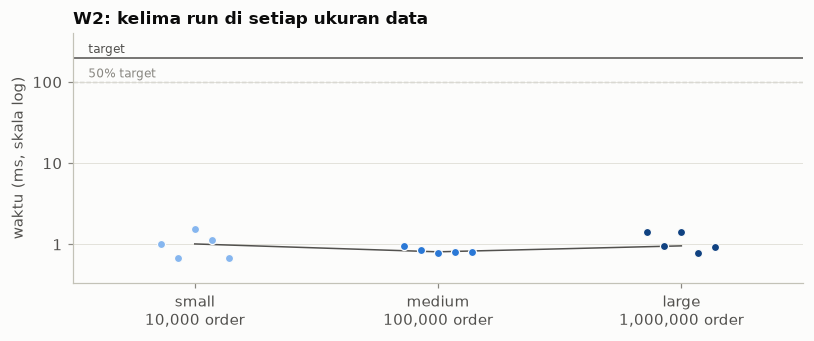

- **Rentang waktu:** small 0,68–1,53 ms, medium 0,78–0,96 ms, large 0,79–1,43 ms.
- **Kepekaan terhadap ukuran data:** setiap kali data naik 10 kali, median-nya menjadi 0,8 kali semula (small ke medium) dan 1,2 kali semula (medium ke large). Eksponen b = 0,02 ± 0,08 (R² 0,03), artinya waktunya tidak terbukti bertambah saat data membesar 100 kali. R² yang rendah wajar di sini, karena tidak ada tren yang bisa dijelaskan, hanya variasi kecil antar-run.
- **Standar deviasi:** SD 0,35 / 0,07 / 0,30 ms, atau CV 35,0% / 8,2% / 27,4% (small / medium / large). CV di small dan large 15% atau lebih. Dalam milidetik, selisih run terlambat dengan median-nya 0,51 ms di small dan 0,47 ms di large.
- **Threshold:** 0 dari 15 run melewati target. 0 dari 15 run ada di zona waspada (≥ 50% target). 3 dari 15 run termasuk outlier (lebih dari 1,2 kali median): run ke-3 di small (1,53 ms, median 1,01 ms), run ke-1 di large (1,43 ms, median 0,96 ms) dan run ke-3 di large (1,43 ms, median 0,96 ms).

In [18]:
analyze('W2')

### W3: Driver Accepts Assignment & Starts Trip

**Maksud query:** driver menerima tawaran dari W2. Dalam satu transaksi, assignment menjadi ACCEPTED dan waktu responsnya dicatat, lalu trip berubah dari SEARCHING ke ALLOCATED, kemudian ke IN_PROGRESS saat perjalanan dimulai.

**Yang bisa didapat:** trip TRP9999001 yang sedang berjalan dengan driver yang sudah menerima tawarannya.

**Kategori:** transaksional. **Target:** 200 ms. **Baris diubah (small / medium / large):** 3 / 3 / 3.

,min (ms),median (ms),max (ms),mean (ms),SD (ms),CV (%),run > target,run ≥ 50% target,"run > 1,2× median"
ukuran data,,,,,,,,,
small,0.93,1.02,1.13,1.02,0.07,7.03,0/5,0/5,0/5
medium,1.13,1.17,1.18,1.16,0.02,1.98,0/5,0/5,0/5
large,1.52,1.73,2.34,1.81,0.32,17.92,0/5,0/5,1/5


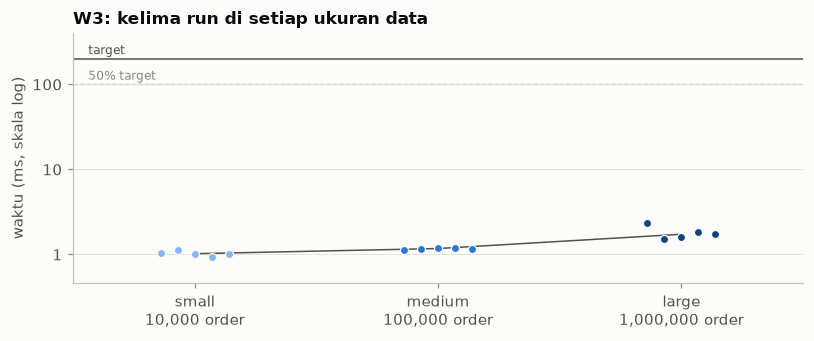

- **Rentang waktu:** small 0,93–1,13 ms, medium 1,13–1,18 ms, large 1,52–2,34 ms.
- **Kepekaan terhadap ukuran data:** setiap kali data naik 10 kali, median-nya menjadi 1,1 kali semula (small ke medium) dan 1,5 kali semula (medium ke large). Eksponen b = 0,12 ± 0,04 (R² 0,79), artinya waktunya bertambah, tetapi lebih lambat dari pertumbuhan data.
- **Standar deviasi:** SD 0,07 / 0,02 / 0,32 ms, atau CV 7,0% / 2,0% / 17,9% (small / medium / large). CV di large 15% atau lebih. Dalam milidetik, selisih run terlambat dengan median-nya 0,61 ms di large.
- **Threshold:** 0 dari 15 run melewati target. 0 dari 15 run ada di zona waspada (≥ 50% target). 1 dari 15 run termasuk outlier (lebih dari 1,2 kali median): run ke-1 di large (2,34 ms, median 1,73 ms).

In [19]:
analyze('W3')

### W4: Driver Rejects Assignment / Expiry Handler

**Maksud query:** menangani driver yang menolak tawaran. Seperti W1, order cash baru ORD9999002 dikonfirmasi lebih dulu, lalu trip TRP9999002 dibuat dan ditawarkan ke kendaraan kedua. Driver menolaknya dengan alasan "Too far from pickup location".

**Yang bisa didapat:** assignment REJECTED yang mencatat waktu respons, waktu berakhir, dan alasan penolakan. Trip-nya tetap SEARCHING, sehingga masih bisa ditawarkan ke driver lain.

**Kategori:** transaksional. **Target:** 200 ms. **Baris diubah (small / medium / large):** 6 / 6 / 6.

,min (ms),median (ms),max (ms),mean (ms),SD (ms),CV (%),run > target,run ≥ 50% target,"run > 1,2× median"
ukuran data,,,,,,,,,
small,2.62,3.05,3.63,3.05,0.39,12.87,0/5,0/5,0/5
medium,3.24,3.69,3.92,3.68,0.28,7.64,0/5,0/5,0/5
large,12.66,12.75,14.63,13.20,0.84,6.33,0/5,0/5,0/5


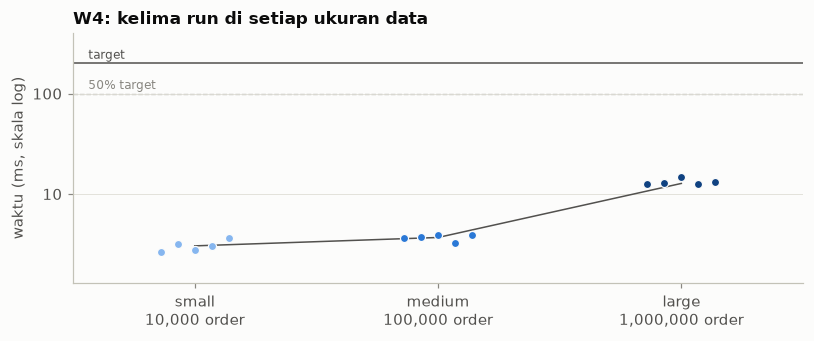

- **Rentang waktu:** small 2,62–3,63 ms, medium 3,24–3,92 ms, large 12,7–14,6 ms.
- **Kepekaan terhadap ukuran data:** setiap kali data naik 10 kali, median-nya menjadi 1,2 kali semula (small ke medium) dan 3,5 kali semula (medium ke large). Eksponen b = 0,32 ± 0,09 (R² 0,83), artinya waktunya bertambah, tetapi lebih lambat dari pertumbuhan data.
- **Standar deviasi:** SD 0,39 / 0,28 / 0,84 ms, atau CV 12,9% / 7,6% / 6,3% (small / medium / large). Ketiganya di bawah 15%, jadi variasinya masih wajar.
- **Threshold:** 0 dari 15 run melewati target. 0 dari 15 run ada di zona waspada (≥ 50% target). 0 dari 15 run termasuk outlier (lebih dari 1,2 kali median).

In [20]:
analyze('W4')

### W5: Complete Trip & Release Driver Availability

**Maksud query:** menyelesaikan trip TRP9999001 dari W3. Dalam satu transaksi, trip menjadi COMPLETED, assignment yang diterima ditutup dengan mengisi `ended_at`, dan driver-nya kembali berstatus ACTIVE.

**Yang bisa didapat:** trip yang tercatat selesai, dan driver yang tersedia lagi untuk menerima order berikutnya.

**Kategori:** transaksional. **Target:** 200 ms. **Baris diubah (small / medium / large):** 3 / 3 / 3.

,min (ms),median (ms),max (ms),mean (ms),SD (ms),CV (%),run > target,run ≥ 50% target,"run > 1,2× median"
ukuran data,,,,,,,,,
small,1.43,1.44,1.82,1.53,0.16,10.81,0/5,0/5,1/5
medium,1.32,1.56,1.66,1.50,0.14,9.53,0/5,0/5,0/5
large,1.96,1.99,3.24,2.26,0.55,24.45,0/5,0/5,1/5


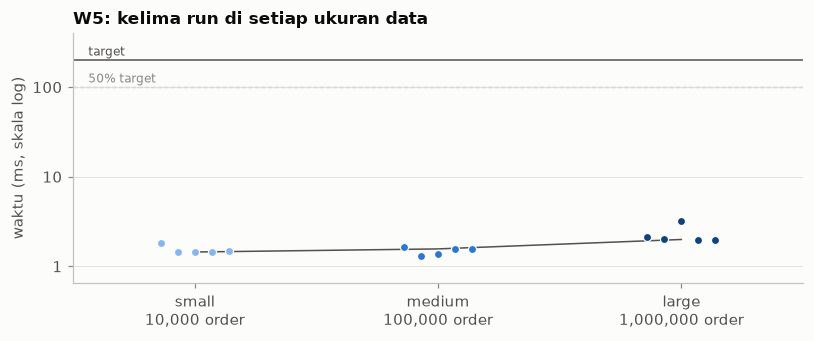

- **Rentang waktu:** small 1,43–1,82 ms, medium 1,32–1,66 ms, large 1,96–3,24 ms.
- **Kepekaan terhadap ukuran data:** setiap kali data naik 10 kali, median-nya menjadi 1,1 kali semula (small ke medium) dan 1,3 kali semula (medium ke large). Eksponen b = 0,08 ± 0,05 (R² 0,47), artinya waktunya bertambah, tetapi lebih lambat dari pertumbuhan data.
- **Standar deviasi:** SD 0,16 / 0,14 / 0,55 ms, atau CV 10,8% / 9,5% / 24,4% (small / medium / large). CV di large 15% atau lebih. Dalam milidetik, selisih run terlambat dengan median-nya 1,25 ms di large.
- **Threshold:** 0 dari 15 run melewati target. 0 dari 15 run ada di zona waspada (≥ 50% target). 2 dari 15 run termasuk outlier (lebih dari 1,2 kali median): run ke-1 di small (1,82 ms, median 1,44 ms) dan run ke-3 di large (3,24 ms, median 1,99 ms).

In [21]:
analyze('W5')

### W6: Onboard a New Service Area with Its Locations and Outlets

**Maksud query:** mendaftarkan service area baru, Cicendo di Bandung, beserta 3 lokasi dan 2 outlet pertamanya dalam satu transaksi. Dengan begitu area, lokasi, dan outlet tersimpan bersama atau tidak sama sekali.

**Yang bisa didapat:** service area baru yang langsung bisa dipakai. Lokasinya dipakai oleh ride di W7–W9, dan area ini dinonaktifkan lagi di W10.

**Kategori:** transaksional. **Target:** 200 ms. **Baris diubah (small / medium / large):** 6 / 6 / 6.

,min (ms),median (ms),max (ms),mean (ms),SD (ms),CV (%),run > target,run ≥ 50% target,"run > 1,2× median"
ukuran data,,,,,,,,,
small,1.61,1.67,1.85,1.70,0.10,5.84,0/5,0/5,0/5
medium,1.32,1.38,1.64,1.44,0.14,9.65,0/5,0/5,0/5
large,1.52,1.76,2.15,1.82,0.30,16.31,0/5,0/5,1/5


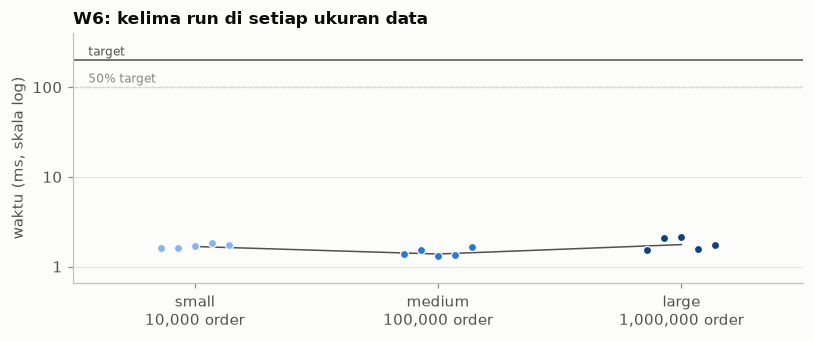

- **Rentang waktu:** small 1,61–1,85 ms, medium 1,32–1,64 ms, large 1,52–2,15 ms.
- **Kepekaan terhadap ukuran data:** setiap kali data naik 10 kali, median-nya menjadi 0,8 kali semula (small ke medium) dan 1,3 kali semula (medium ke large). Eksponen b = 0,01 ± 0,04 (R² 0,03), artinya waktunya tidak terbukti bertambah saat data membesar 100 kali. R² yang rendah wajar di sini, karena tidak ada tren yang bisa dijelaskan, hanya variasi kecil antar-run.
- **Standar deviasi:** SD 0,10 / 0,14 / 0,30 ms, atau CV 5,8% / 9,7% / 16,3% (small / medium / large). CV di large 15% atau lebih. Dalam milidetik, selisih run terlambat dengan median-nya 0,39 ms di large.
- **Threshold:** 0 dari 15 run melewati target. 0 dari 15 run ada di zona waspada (≥ 50% target). 1 dari 15 run termasuk outlier (lebih dari 1,2 kali median): run ke-3 di large (2,15 ms, median 1,76 ms).

In [22]:
analyze('W6')

### W7: Checkout with Non-Cash Payment Retry

**Maksud query:** meniru checkout dengan pembayaran non-tunai (E_WALLET) yang gagal sekali, lalu berhasil saat dicoba ulang. Status payment mengikuti trigger transisi: PENDING → FAILED → PENDING → PAID. Order, mobility order, dan payment dibuat dalam satu transaksi, karena trigger spesialisasi baru diperiksa saat COMMIT.

**Yang bisa didapat:** order ORD9999101 yang baru menjadi CONFIRMED setelah payment-nya PAID, dan trip TRP9999101 yang mulai mencari driver di lokasi dari W6.

**Kategori:** transaksional. **Target:** 200 ms. **Baris diubah (small / medium / large):** 8 / 8 / 8.

,min (ms),median (ms),max (ms),mean (ms),SD (ms),CV (%),run > target,run ≥ 50% target,"run > 1,2× median"
ukuran data,,,,,,,,,
small,2.82,3.20,3.44,3.17,0.26,8.03,0/5,0/5,0/5
medium,2.84,3.03,3.62,3.18,0.33,10.29,0/5,0/5,0/5
large,3.36,3.48,4.30,3.64,0.38,10.33,0/5,0/5,1/5


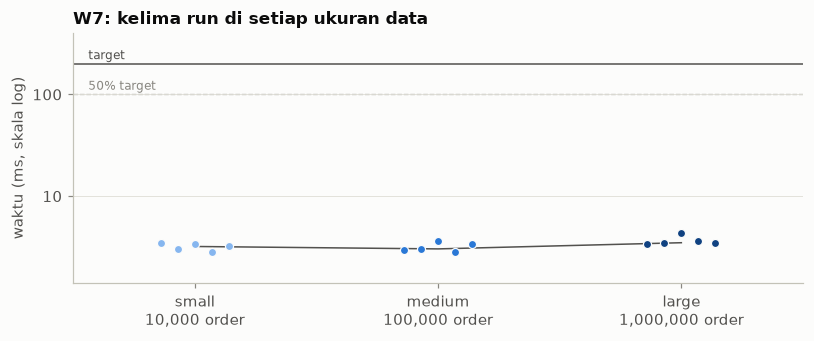

- **Rentang waktu:** small 2,82–3,44 ms, medium 2,84–3,62 ms, large 3,36–4,30 ms.
- **Kepekaan terhadap ukuran data:** setiap kali data naik 10 kali, median-nya menjadi 0,9 kali semula (small ke medium) dan 1,2 kali semula (medium ke large). Eksponen b = 0,03 ± 0,03 (R² 0,27), artinya waktunya bertambah, tetapi lebih lambat dari pertumbuhan data.
- **Standar deviasi:** SD 0,26 / 0,33 / 0,38 ms, atau CV 8,0% / 10,3% / 10,3% (small / medium / large). Ketiganya di bawah 15%, jadi variasinya masih wajar.
- **Threshold:** 0 dari 15 run melewati target. 0 dari 15 run ada di zona waspada (≥ 50% target). 1 dari 15 run termasuk outlier (lebih dari 1,2 kali median): run ke-3 di large (4,30 ms, median 3,48 ms).

In [23]:
analyze('W7')

### W8: Customer Cancels Before Pickup with Payment Settlement

**Maksud query:** customer membatalkan order ORD9999101 dari W7 sebelum dijemput. Dalam satu transaksi, order menjadi CANCELLED, trip dan assignment-nya dibatalkan, lalu payment diselesaikan: yang sudah PAID di-refund dengan `paid_at` tetap, dan yang masih PENDING menjadi FAILED.

**Yang bisa didapat:** pembatalan yang konsisten di semua tabel. Setiap langkah hanya mengubah data kalau order-nya benar-benar dibatalkan, sehingga order yang sudah IN_PROGRESS tidak ikut berubah.

**Kategori:** transaksional. **Target:** 200 ms. **Baris diubah (small / medium / large):** 3 / 3 / 3.

,min (ms),median (ms),max (ms),mean (ms),SD (ms),CV (%),run > target,run ≥ 50% target,"run > 1,2× median"
ukuran data,,,,,,,,,
small,1.32,1.49,1.75,1.52,0.16,10.20,0/5,0/5,0/5
medium,1.21,1.37,1.74,1.44,0.21,14.67,0/5,0/5,1/5
large,1.46,1.76,2.30,1.77,0.33,18.90,0/5,0/5,1/5


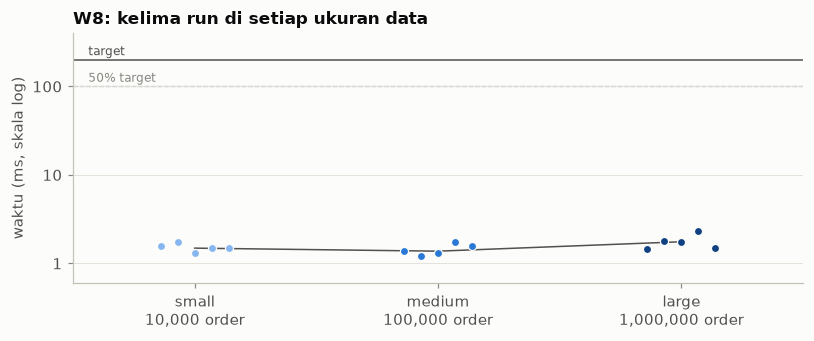

- **Rentang waktu:** small 1,32–1,75 ms, medium 1,21–1,74 ms, large 1,46–2,30 ms.
- **Kepekaan terhadap ukuran data:** setiap kali data naik 10 kali, median-nya menjadi 0,9 kali semula (small ke medium) dan 1,3 kali semula (medium ke large). Eksponen b = 0,03 ± 0,05 (R² 0,14), artinya waktunya tidak terbukti bertambah saat data membesar 100 kali. R² yang rendah wajar di sini, karena tidak ada tren yang bisa dijelaskan, hanya variasi kecil antar-run.
- **Standar deviasi:** SD 0,16 / 0,21 / 0,33 ms, atau CV 10,2% / 14,7% / 18,9% (small / medium / large). CV di large 15% atau lebih. Dalam milidetik, selisih run terlambat dengan median-nya 0,54 ms di large.
- **Threshold:** 0 dari 15 run melewati target. 0 dari 15 run ada di zona waspada (≥ 50% target). 2 dari 15 run termasuk outlier (lebih dari 1,2 kali median): run ke-4 di medium (1,74 ms, median 1,37 ms) dan run ke-4 di large (2,30 ms, median 1,76 ms).

In [24]:
analyze('W8')

### W9: Complete a Cash Ride and Collect the Payment (Transactional Query)

**Maksud query:** query transaksional: driver menyelesaikan ride tunai dan menerima uang dari customer. Transaksi pertama menyiapkan ride tunai yang sedang berjalan di lokasi dari W6. Transaksi kedua mengubah trip dan order menjadi COMPLETED, dan payment cash yang PENDING menjadi PAID.

**Yang bisa didapat:** trip, order, dan payment yang berubah bersama. Kalau salah satu UPDATE gagal, misalnya ditolak trigger transisi status, seluruh transaksi batal, sehingga tidak ada ride yang tercatat selesai tanpa pembayaran.

**Kategori:** transaksional. **Target:** 200 ms. **Baris diubah (small / medium / large):** 7 / 7 / 7.

,min (ms),median (ms),max (ms),mean (ms),SD (ms),CV (%),run > target,run ≥ 50% target,"run > 1,2× median"
ukuran data,,,,,,,,,
small,1.87,2.05,2.36,2.12,0.20,9.43,0/5,0/5,0/5
medium,2.11,2.45,2.86,2.44,0.30,12.15,0/5,0/5,0/5
large,1.99,2.24,3.50,2.57,0.62,24.12,0/5,0/5,2/5


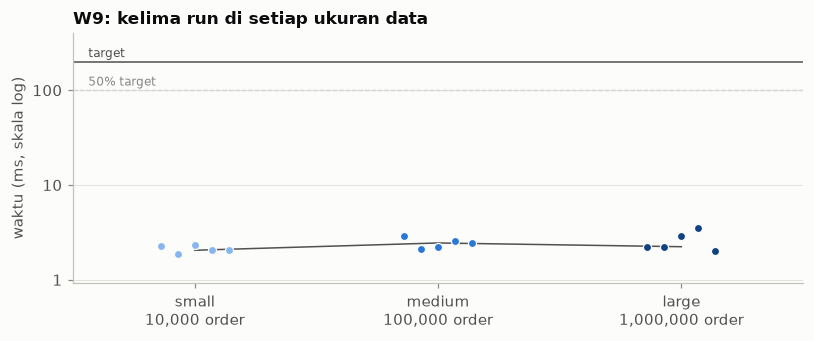

- **Rentang waktu:** small 1,87–2,36 ms, medium 2,11–2,86 ms, large 1,99–3,50 ms.
- **Kepekaan terhadap ukuran data:** setiap kali data naik 10 kali, median-nya menjadi 1,2 kali semula (small ke medium) dan 0,9 kali semula (medium ke large). Eksponen b = 0,04 ± 0,05 (R² 0,19), artinya waktunya tidak terbukti bertambah saat data membesar 100 kali. R² yang rendah wajar di sini, karena tidak ada tren yang bisa dijelaskan, hanya variasi kecil antar-run.
- **Standar deviasi:** SD 0,20 / 0,30 / 0,62 ms, atau CV 9,4% / 12,2% / 24,1% (small / medium / large). CV di large 15% atau lebih. Dalam milidetik, selisih run terlambat dengan median-nya 1,27 ms di large.
- **Threshold:** 0 dari 15 run melewati target. 0 dari 15 run ada di zona waspada (≥ 50% target). 2 dari 15 run termasuk outlier (lebih dari 1,2 kali median): run ke-3 di large (2,89 ms, median 2,24 ms) dan run ke-4 di large (3,50 ms, median 2,24 ms).

In [25]:
analyze('W9')

### W10: Deactivate a Service Area and Delist Its Outlets

**Maksud query:** menonaktifkan service area Cicendo dari W6 beserta outlet di semua lokasinya, misalnya karena uji coba layanan di area itu dihentikan. Query ini dijalankan paling akhir, setelah ride di area ini (W7–W9).

**Yang bisa didapat:** service area yang INACTIVE. Outlet yang tidak punya food order berjalan (PENDING, CONFIRMED, atau IN_PROGRESS) langsung menjadi INACTIVE, sedangkan outlet yang masih punya order berjalan hanya ditutup (CLOSED), supaya order-nya tetap bisa diselesaikan.

**Kategori:** transaksional. **Target:** 200 ms. **Baris diubah (small / medium / large):** 3 / 3 / 3.

,min (ms),median (ms),max (ms),mean (ms),SD (ms),CV (%),run > target,run ≥ 50% target,"run > 1,2× median"
ukuran data,,,,,,,,,
small,1.32,1.36,1.47,1.37,0.06,4.31,0/5,0/5,0/5
medium,4.41,4.59,5.45,4.75,0.43,9.00,0/5,0/5,0/5
large,38.39,45.74,58.14,48.28,8.64,17.90,0/5,0/5,2/5


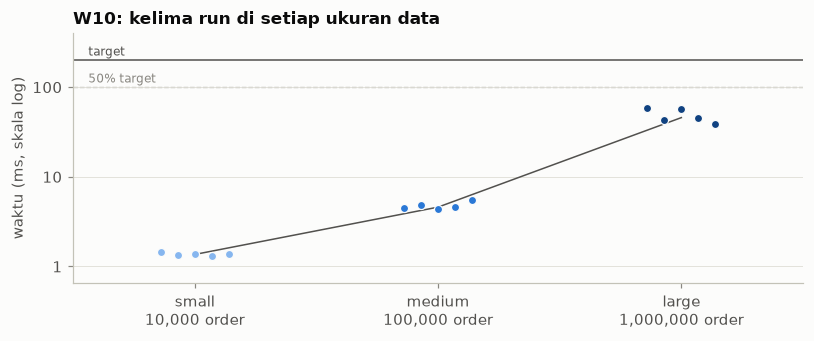

- **Rentang waktu:** small 1,32–1,47 ms, medium 4,41–5,45 ms, large 38,4–58,1 ms.
- **Kepekaan terhadap ukuran data:** setiap kali data naik 10 kali, median-nya menjadi 3,4 kali semula (small ke medium) dan 10,0 kali semula (medium ke large). Eksponen b = 0,77 ± 0,09 (R² 0,97), artinya waktunya bertambah, tetapi lebih lambat dari pertumbuhan data.
- **Standar deviasi:** SD 0,06 / 0,43 / 8,64 ms, atau CV 4,3% / 9,0% / 17,9% (small / medium / large). CV di large 15% atau lebih. Dalam milidetik, selisih run terlambat dengan median-nya 12,4 ms di large.
- **Threshold:** 0 dari 15 run melewati target. 0 dari 15 run ada di zona waspada (≥ 50% target). 2 dari 15 run termasuk outlier (lebih dari 1,2 kali median): run ke-1 di large (58,1 ms, median 45,7 ms) dan run ke-3 di large (56,4 ms, median 45,7 ms).

In [26]:
analyze('W10')

## 5. Analisis keseluruhan

Setelah setiap query dibahas sendiri-sendiri, bagian ini membandingkan semua query sekaligus.

### 5.1 Rekap semua query

Tabel ini merangkum bagian 3 dan 4, satu baris per query.
- **median (ms):** waktu median dari lima run di setiap ukuran data. Untuk write yang terdiri dari beberapa statement, waktunya adalah total semua statement.
- **rentang large (ms):** run tercepat sampai run terlambat di large.
- **eksponen b:** kepekaan terhadap ukuran data, dengan interval kepercayaan 95% (bagian 2).
- **CV maks (%):** koefisien variasi terbesar di antara ketiga ukuran data.
- **Kolom run:** jumlah run yang melewati setiap threshold, dari semua run query itu di ketiga ukuran data.

In [27]:
recap_rows = []
for query in QUERY_ORDER:
    frame = bench[bench['query'] == query].set_index('profile').loc[PROFILES]
    row = {'query': query, 'kategori': category(query)}
    for profile in PROFILES:
        row[f'median {profile} (ms)'] = np.round(frame.loc[profile, 'median_ms'], 2)
    row['rentang large (ms)'] = (f"{np.round(frame.loc['large', 'min_ms'], 1):,.1f}–"
                                 f"{np.round(frame.loc['large', 'max_ms'], 1):,.1f}")
    row['eksponen b'] = f"{fits[query]['b']:.2f} ± {fits[query]['ci']:.2f}"
    row['CV maks (%)'] = np.round(frame['cv_pct'].max(), 1)
    for label, key in THRESHOLDS:
        row[label] = f"{int(frame[key].sum())}/{int(frame['runs'].sum())}"
    recap_rows.append(row)
display(pd.DataFrame(recap_rows).set_index('query'))

,kategori,median small (ms),median medium (ms),median large (ms),rentang large (ms),eksponen b,CV maks (%),run > target,run ≥ 50% target,"run > 1,2× median"
query,,,,,,,,,,
R1,Analitik,6.95,53.51,605.87,576.1–794.0,0.98 ± 0.04,13.9,0/15,0/15,1/15
R2,Analitik,7.94,73.49,1041.01,"1,030.0–1,240.9",1.05 ± 0.05,15.1,0/15,5/15,1/15
R3,Analitik,20.38,271.42,1553.20,"1,501.4–1,626.2",0.94 ± 0.07,3.9,0/15,5/15,0/15
R4,Analitik,6.12,63.01,603.87,588.2–620.2,1.00 ± 0.02,7.6,0/15,0/15,0/15
R5,Analitik,3.49,35.82,149.43,143.8–154.3,0.81 ± 0.07,5.0,0/15,0/15,0/15
R6,Analitik,10.22,121.65,849.36,834.5–867.4,0.96 ± 0.04,11.1,0/15,0/15,0/15
R7,Analitik,6.76,85.99,531.24,518.5–538.2,0.95 ± 0.06,9.2,0/15,0/15,0/15
R8,Analitik,6.15,100.08,584.22,563.8–594.6,0.98 ± 0.08,7.8,0/15,0/15,0/15
R9,Analitik,1.94,14.00,103.32,97.4–106.9,0.87 ± 0.01,4.3,0/15,0/15,0/15


### 5.2 Waktu median semua query

Grafik di bawah menampilkan waktu median setiap query di ketiga ukuran data, sehingga semua query bisa dibandingkan sekaligus.
- **Warna batang:** semakin gelap, semakin besar datanya (small, medium, large).
- **Sumbu tegak:** memakai skala log, karena waktunya berkisar dari kurang dari 1 ms sampai lebih dari 1 detik. Pada skala log, setiap garis bantu berarti 10 kali lebih lama dari garis di bawahnya.
- **Garis kecil di setiap batang:** rentang dari run tercepat sampai run terlambat di antara 5 run. Garis yang pendek berarti waktunya konsisten.

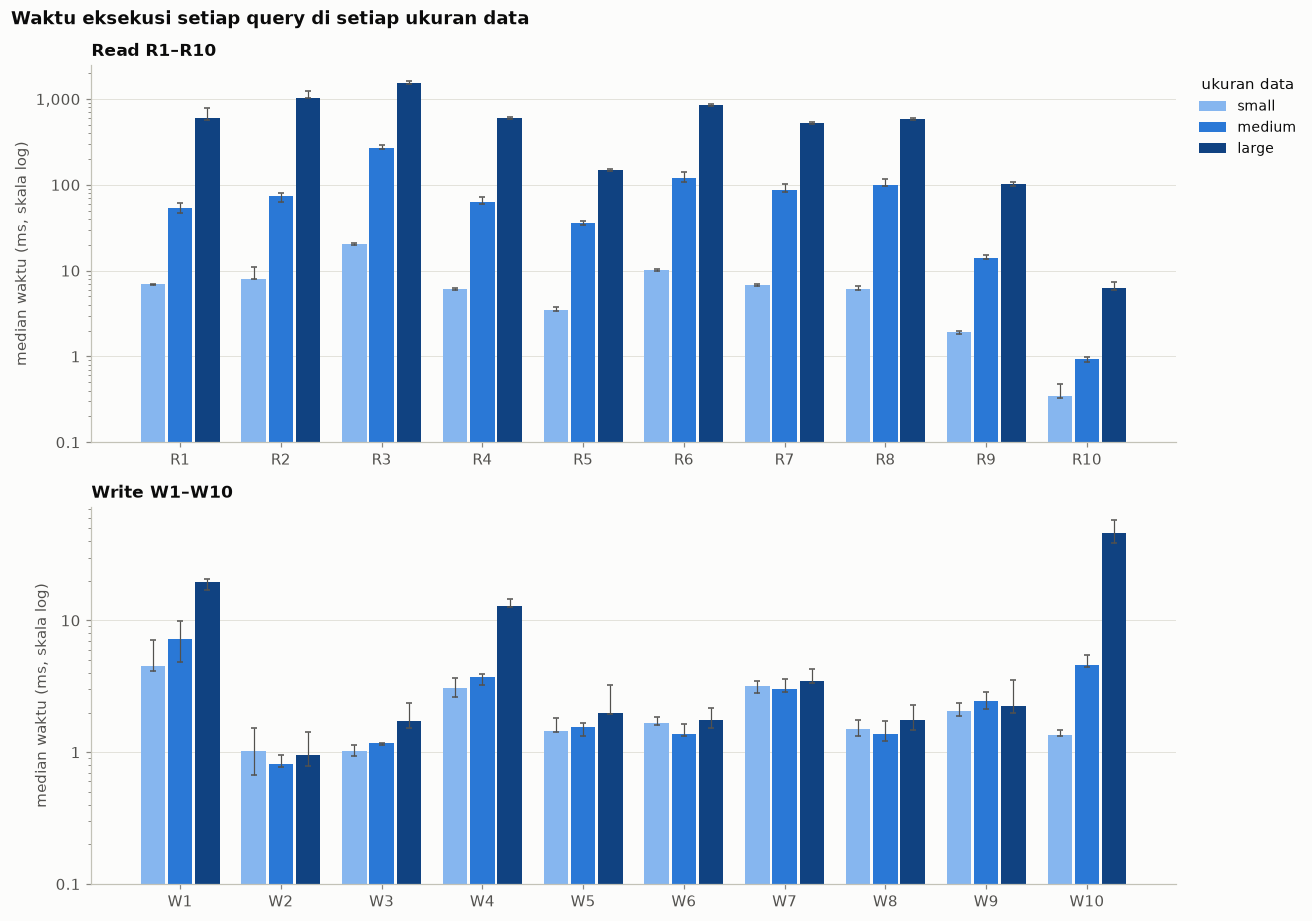

In [28]:
PROFILE_COLORS = {'small': '#86b6ef', 'medium': '#2a78d6', 'large': '#104281'}
width = 0.27
fig, axes = plt.subplots(2, 1, figsize=(12, 8.5))
for ax, prefix, title in [(axes[0], 'R', 'Read R1–R10'), (axes[1], 'W', 'Write W1–W10')]:
    queries = [q for q in QUERY_ORDER if q.startswith(prefix)]
    for i, profile in enumerate(PROFILES):
        frame = bench[bench['profile'] == profile].set_index(bench.loc[bench['profile'] == profile, 'query']
                                                            .astype(str)).loc[queries]
        xs = [k + (i - 1) * width for k in range(len(queries))]
        ax.bar(xs, frame['median_ms'], width=width * 0.9, color=PROFILE_COLORS[profile], label=profile, zorder=2)
        ax.errorbar(xs, frame['median_ms'], yerr=[frame['median_ms'] - frame['min_ms'],
                                                  frame['max_ms'] - frame['median_ms']],
                    fmt='none', ecolor=INK_2, elinewidth=0.8, capsize=2, zorder=3)
    ax.set_yscale('log')
    ax.yaxis.set_major_formatter(PLAIN)
    ax.set_ylim(bottom=0.1)
    ax.set_xticks(range(len(queries)), labels=queries)
    ax.grid(axis='x', visible=False)
    ax.set_ylabel('median waktu (ms, skala log)')
    ax.set_title(title)
axes[0].legend(title='ukuran data', loc='upper left', bbox_to_anchor=(1.01, 1.0))
fig.suptitle('Waktu eksekusi setiap query di setiap ukuran data', x=0.01, ha='left', fontsize=12, fontweight='bold')
fig.tight_layout()
plt.show()

In [29]:
medians = bench.pivot_table(index='query', columns='profile', values='median_ms', observed=True)
growth = (medians['large'] / medians['small']).rename(index=str)
steep = growth[growth >= 10].sort_values(ascending=False)
flat = growth[growth < 2]
say('Dari grafik ini terlihat dua kelompok yang jelas:\n'
    f'- **Batangnya naik tajam dari small ke large:** {names(steep.index)}. Waktunya bertambah '
    f'{growth[steep.index].min():.0f}–{growth[steep.index].max():.0f} kali saat data 100 kali lebih besar. '
    'Hampir semuanya query analitik, yang memang harus membaca seluruh data.\n'
    f'- **Batangnya hampir sama tinggi di ketiga ukuran data:** {names(flat.index)}. Waktunya bertambah kurang dari '
    '2 kali, karena query ini langsung menuju baris yang dicari lewat index.')

Dari grafik ini terlihat dua kelompok yang jelas:
- **Batangnya naik tajam dari small ke large:** R2, R4, R8, R1, R6, R7, R3, R9, R5, W10 dan R10. Waktunya bertambah 18–131 kali saat data 100 kali lebih besar. Hampir semuanya query analitik, yang memang harus membaca seluruh data.
- **Batangnya hampir sama tinggi di ketiga ukuran data:** W2, W3, W5, W6, W7, W8 dan W9. Waktunya bertambah kurang dari 2 kali, karena query ini langsung menuju baris yang dicari lewat index.

### 5.3 Load test: ukuran data normal

Di small dan medium, harapannya semua query lulus dengan mudah. Angka di tabel adalah run paling lambat dari lima run.

In [30]:
table, passed = verdict_table(['small', 'medium'])
display(table)
display(Markdown(f'**Lulus:** {passed}'))

small (run terlambat) medium (run terlambat)
kategori      query                                             
Analitik      R1           7.1 ms (lulus)        60.8 ms (lulus)
              R2          10.9 ms (lulus)        80.7 ms (lulus)
              R3          20.8 ms (lulus)       290.0 ms (lulus)
              R4           6.3 ms (lulus)        72.9 ms (lulus)
              R5           3.7 ms (lulus)        37.8 ms (lulus)
              R6          10.4 ms (lulus)       142.0 ms (lulus)
              R7           7.1 ms (lulus)       102.6 ms (lulus)
              R8           6.6 ms (lulus)       116.9 ms (lulus)
              R9           2.0 ms (lulus)        15.1 ms (lulus)
Operasional   R10          0.5 ms (lulus)         1.0 ms (lulus)
Transaksional W1           7.1 ms (lulus)         9.9 ms (lulus)
              W2           1.5 ms (lulus)         1.0 ms (lulus)
              W3           1.1 ms (lulus)         1.2 ms (lulus)
              W4           3.6 ms (lulus)         3.9 ms (lulus)
              W5           1.8 ms (lulus)         1.7 ms (lulus)
              W6           1.8 ms (lulus)         1.6 ms (lulus)
              W7           3.4 ms (lulus)         3.6 ms (lulus)
              W8           1.7 ms (lulus)         1.7 ms (lulus)
              W9           2.4 ms (lulus)         2.9 ms (lulus)
              W10          1.5 ms (lulus)         5.5 ms (lulus)

**Lulus:** small 20/20, medium 20/20

In [31]:
normal = bench[bench['profile'].isin(['small', 'medium'])]
failed_normal = normal[~normal['passes']]
medium_rows = bench[bench['profile'] == 'medium']
slowest = medium_rows.loc[medium_rows['max_ms'].idxmax()]
write_max = normal.loc[normal['category'] == 'Transaksional', 'max_ms'].max()
opening = ('Hasilnya sesuai harapan: semua lulus.' if failed_normal.empty else
           'Tidak semuanya lulus: ' + names(f"{r['query']} di {r['profile']}" for _, r in failed_normal.iterrows())
           + ' melewati targetnya.')
say(f"{opening}\n"
    f"- **Query paling lambat di medium:** {slowest['query']}, dengan {ms_text(slowest['max_ms'])}, "
    f"dari batas {ms_text(slowest['slo_ms'])}.\n"
    f"- **Semua write:** selesai dalam paling lama {ms_text(write_max)}.")

Hasilnya sesuai harapan: semua lulus.
- **Query paling lambat di medium:** R3, dengan 290 ms, dari batas 2 detik.
- **Semua write:** selesai dalam paling lama 9,9 ms.

### 5.4 Stress test: ukuran data besar

Di large, datanya 100 kali lebih besar dari small. Di sini kita tidak hanya bertanya lulus atau tidak, tetapi juga seberapa cepat waktunya bertambah. Kolom `medium → large` adalah berapa kali lebih lambat sebuah query saat datanya naik 10 kali. Eksponen b dan R² dijelaskan di bagian 2.

In [32]:
wide = bench.pivot_table(index='query', columns='profile', values='median_ms', observed=True)
stress = pd.DataFrame({
    'kategori': large['category'],
    'median large (ms)': large['median_ms'].round(1),
    'run terlambat (ms)': large['max_ms'].round(1),
    'target (ms)': large['slo_ms'],
    'hasil': large['passes'].map({True: 'lulus', False: 'gagal'}),
    'medium → large': (wide['large'] / wide['medium']).map('{:.1f}×'.format),
    'eksponen b (± interval kepercayaan 95%)': [f"{fits[str(q)]['b']:.2f} ± {fits[str(q)]['ci']:.2f}" for q in large.index],
    'R² (kecocokan model)': [round(fits[str(q)]['r2'], 2) for q in large.index],
})
display(stress.loc[[q for q in QUERY_ORDER if q in stress.index]])
display(Markdown(f"**Lulus di large:** {int(large['passes'].sum())}/{len(large)}"))

,kategori,median large (ms),run terlambat (ms),target (ms),hasil,medium → large,eksponen b (± interval kepercayaan 95%),R² (kecocokan model)
query,,,,,,,,
R1,Analitik,605.9,794.0,2000,lulus,11.3×,0.98 ± 0.04,0.99
R2,Analitik,1041.0,1240.9,2000,lulus,14.2×,1.05 ± 0.05,0.99
R3,Analitik,1553.2,1626.2,2000,lulus,5.7×,0.94 ± 0.07,0.99
R4,Analitik,603.9,620.2,2000,lulus,9.6×,1.00 ± 0.02,1.00
R5,Analitik,149.4,154.3,2000,lulus,4.2×,0.81 ± 0.07,0.98
R6,Analitik,849.4,867.4,2000,lulus,7.0×,0.96 ± 0.04,0.99
R7,Analitik,531.2,538.2,2000,lulus,6.2×,0.95 ± 0.06,0.99
R8,Analitik,584.2,594.6,2000,lulus,5.8×,0.98 ± 0.08,0.98
R9,Analitik,103.3,106.9,2000,lulus,7.4×,0.87 ± 0.01,1.00


**Lulus di large:** 20/20

In [33]:
large_rows = bench[bench['profile'] == 'large']
failed_large = large_rows[~large_rows['passes']]
if failed_large.empty:
    opening = f'Ke-{len(large_rows)} query masih lulus di large, tetapi tidak semuanya dengan nyaman.'
else:
    opening = (f'{len(large_rows) - len(failed_large)} dari {len(large_rows)} query lulus di large. Yang gagal: '
               + names(f"{r['query']} ({ms_text(r['max_ms'])})" for _, r in failed_large.iterrows()) + '.')
say(opening + ' Grafik di bawah menunjukkan seberapa dekat setiap query ke batasnya, di ketiga ukuran data.\n'
    '- **Posisi titik:** run paling lambat, sebagai persen dari target.\n'
    '- **Garis 100%:** batas target. Titik di sebelah kanannya berarti gagal.\n'
    '- **Sumbu:** memakai skala log, karena ada query yang hanya memakai sebagian kecil dari targetnya.')

Ke-20 query masih lulus di large, tetapi tidak semuanya dengan nyaman. Grafik di bawah menunjukkan seberapa dekat setiap query ke batasnya, di ketiga ukuran data.
- **Posisi titik:** run paling lambat, sebagai persen dari target.
- **Garis 100%:** batas target. Titik di sebelah kanannya berarti gagal.
- **Sumbu:** memakai skala log, karena ada query yang hanya memakai sebagian kecil dari targetnya.

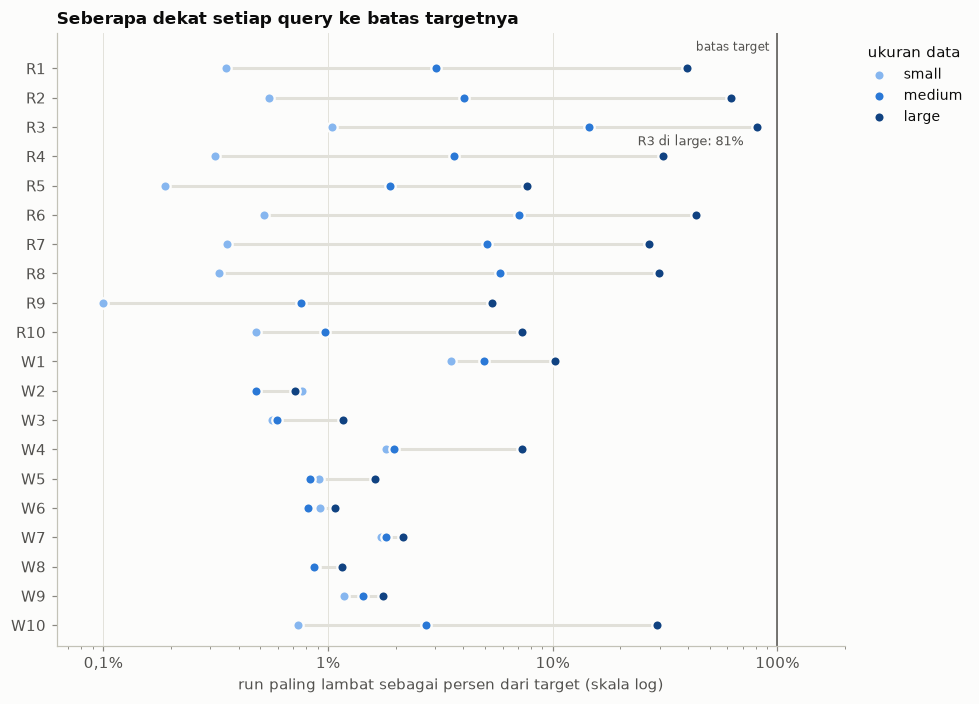

In [34]:
PROFILE_COLORS = {'small': '#86b6ef', 'medium': '#2a78d6', 'large': '#104281'}
usage = bench.assign(pct=100 * bench['max_ms'] / bench['slo_ms'])
order = list(reversed(QUERY_ORDER))
fig, ax = plt.subplots(figsize=(9, 6.5))
for y, query in enumerate(order):
    values = usage[usage['query'] == query].set_index('profile')['pct']
    ax.plot([values.min(), values.max()], [y, y], color=GRID, lw=2, zorder=1)
    for profile in PROFILES:
        ax.scatter(values[profile], y, s=46, color=PROFILE_COLORS[profile], edgecolor=SURFACE, lw=1.5, zorder=3,
                   label=profile if y == 0 else None)
ax.axvline(100, color=INK_2, lw=1, zorder=2)
ax.annotate('batas target', (100, len(order) - 0.4), xytext=(-5, 0), textcoords='offset points', ha='right',
            fontsize=8, color=INK_2)
top = usage.loc[usage['pct'].idxmax()]
ax.annotate(f"{top['query']} di {top['profile']}: {top['pct']:.0f}%".replace('.', ','),
            (top['pct'], order.index(str(top['query']))), xytext=(-9, -12), textcoords='offset points',
            ha='right', fontsize=8.5, color=INK_2)
ax.set_xscale('log')
ax.set_xlim(min(0.1, usage['pct'].min() / 1.6), 200)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v:g}%'.replace('.', ',')))
ax.set_yticks(range(len(order)), labels=order)
ax.set_ylim(-0.7, len(order) + 0.2)
ax.grid(axis='y', visible=False)
ax.set_xlabel('run paling lambat sebagai persen dari target (skala log)')
ax.set_title('Seberapa dekat setiap query ke batas targetnya')
ax.legend(title='ukuran data', loc='upper left', bbox_to_anchor=(1.01, 1.0))
fig.tight_layout()
plt.show()

In [35]:
top = usage.loc[usage['pct'].idxmax()]
analytic_b = exponent[[q for q in exponent.index if category(q) == 'Analitik']]
flat_writes = [q for q in QUERY_ORDER if q.startswith('W') and exponent[q] < 0.2]
say('Semakin besar datanya, semakin ke kanan titiknya.\n'
    f"- **Paling mepet:** {top['query']}, yang di {top['profile']} sudah memakai sekitar {top['pct']:.0f}% "
    'dari targetnya.\n'
    '- **Polanya terbagi dua:**\n'
    f'  - **Query analitik:** b sekitar {dec(analytic_b.min())}–{dec(analytic_b.max())}, artinya waktunya naik '
    'hampir sebanding dengan jumlah data.\n'
    f'  - **{len(flat_writes)} dari 10 write ({names(flat_writes)}):** b mendekati 0, artinya ukuran data hampir '
    'tidak berpengaruh.\n\n'
    'Grafik berikut menggambarkan hal yang sama. Kedua sumbu memakai skala log, jadi makin curam garisnya, makin '
    'peka query itu terhadap ukuran data.\n'
    '- **Panel read:** query analitik digambar abu-abu, dan R10 biru.\n'
    '- **Panel write:** garis oranye adalah write yang waktunya ikut membesar (b > 0,5), sisanya abu-abu.\n'
    '- **Garis horizontal:** batas target.')

Semakin besar datanya, semakin ke kanan titiknya.
- **Paling mepet:** R3, yang di large sudah memakai sekitar 81% dari targetnya.
- **Polanya terbagi dua:**
  - **Query analitik:** b sekitar 0,8–1,0, artinya waktunya naik hampir sebanding dengan jumlah data.
  - **7 dari 10 write (W2, W3, W5, W6, W7, W8 dan W9):** b mendekati 0, artinya ukuran data hampir tidak berpengaruh.

Grafik berikut menggambarkan hal yang sama. Kedua sumbu memakai skala log, jadi makin curam garisnya, makin peka query itu terhadap ukuran data.
- **Panel read:** query analitik digambar abu-abu, dan R10 biru.
- **Panel write:** garis oranye adalah write yang waktunya ikut membesar (b > 0,5), sisanya abu-abu.
- **Garis horizontal:** batas target.

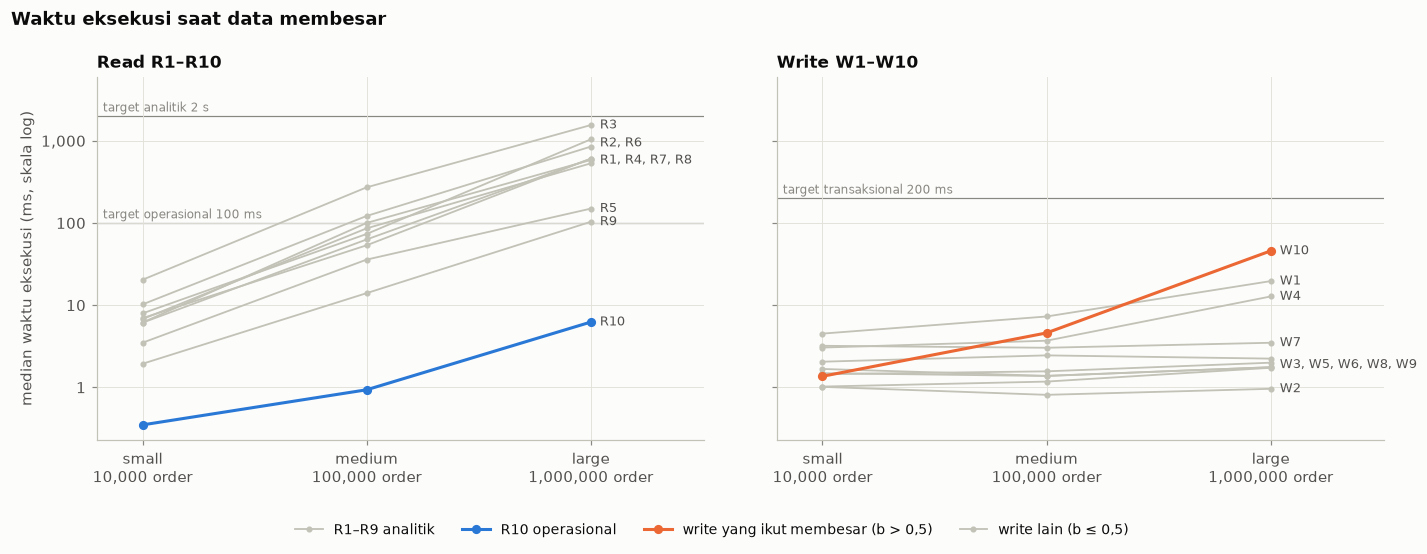

In [36]:
def cluster_labels(ax, frame, value_col, x):
    # Satu label untuk setiap kelompok garis yang ujungnya berdekatan, supaya label tidak bertumpuk.
    ends = frame.sort_values(value_col)
    groups, current = [], []
    for query, value in zip(ends['query'], ends[value_col]):
        if current and value / current[-1][1] > 1.3:
            groups.append(current)
            current = []
        current.append((query, value))
    groups.append(current)
    for group in groups:
        names = ', '.join(sorted((q for q, _ in group), key=QUERY_ORDER.index))
        y = math.exp(sum(math.log(v) for _, v in group) / len(group))
        ax.annotate(names, (x, y), xytext=(6, 0), textcoords='offset points', va='center', fontsize=8.5,
                    color=INK_2)


exp_by_query = exponent.to_dict()
fig, (ax_r, ax_w) = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, prefix in [(ax_r, 'R'), (ax_w, 'W')]:
    frame = bench[bench['query'].astype(str).str.startswith(prefix)]
    for query, group in frame.groupby('query', observed=True):
        if prefix == 'R':
            color = BLUE if query == 'R10' else BACKGROUND
        else:
            color = ORANGE if exp_by_query[query] > 0.5 else BACKGROUND
        focus = color != BACKGROUND
        ax.plot(group['orders'], group['median_ms'], color=color, lw=2 if focus else 1.2,
                marker='o', ms=5 if focus else 3, zorder=3 if focus else 2)
    cluster_labels(ax, frame[frame['profile'] == 'large'].astype({'query': str}), 'median_ms', ORDERS['large'])
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_xticks(list(ORDERS.values()), labels=[f'{p}\n{n:,} order' for p, n in ORDERS.items()])
    ax.minorticks_off()
    ax.yaxis.set_major_formatter(PLAIN)
    ax.set_xlim(ORDERS['small'] / 1.6, ORDERS['large'] * 3.2)
    ax.set_ylim(top=6000)
for ax, slos in [(ax_r, [(2000, 'target analitik 2 s'), (100, 'target operasional 100 ms')]),
                 (ax_w, [(200, 'target transaksional 200 ms')])]:
    for slo, label in slos:
        ax.axhline(slo, color=MUTED, lw=0.8, zorder=1)
        ax.annotate(label, (ORDERS['small'] / 1.6, slo), xytext=(4, 3), textcoords='offset points', fontsize=8,
                    color=MUTED)
ax_r.set_title('Read R1–R10')
ax_w.set_title('Write W1–W10')
ax_r.set_ylabel('median waktu eksekusi (ms, skala log)')
handles = [plt.Line2D([], [], color=BACKGROUND, lw=1.2, marker='o', ms=3, label='R1–R9 analitik'),
           plt.Line2D([], [], color=BLUE, lw=2, marker='o', ms=5, label='R10 operasional'),
           plt.Line2D([], [], color=ORANGE, lw=2, marker='o', ms=5, label='write yang ikut membesar (b > 0,5)'),
           plt.Line2D([], [], color=BACKGROUND, lw=1.2, marker='o', ms=3, label='write lain (b ≤ 0,5)')]
fig.legend(handles=handles, loc='lower center', ncol=4, bbox_to_anchor=(0.5, 0.0))
fig.suptitle('Waktu eksekusi saat data membesar', x=0.01, ha='left', fontsize=12, fontweight='bold')
fig.subplots_adjust(left=0.07, right=0.97, top=0.86, bottom=0.2, wspace=0.12)
plt.show()

Kalau semua query diurutkan berdasarkan eksponen b, terlihat jelas mana yang peka terhadap ukuran data dan mana yang tidak. Garis kecil di ujung batang adalah interval kepercayaan 95%. Interval yang sempit berarti polanya sangat konsisten di ketiga ukuran data.

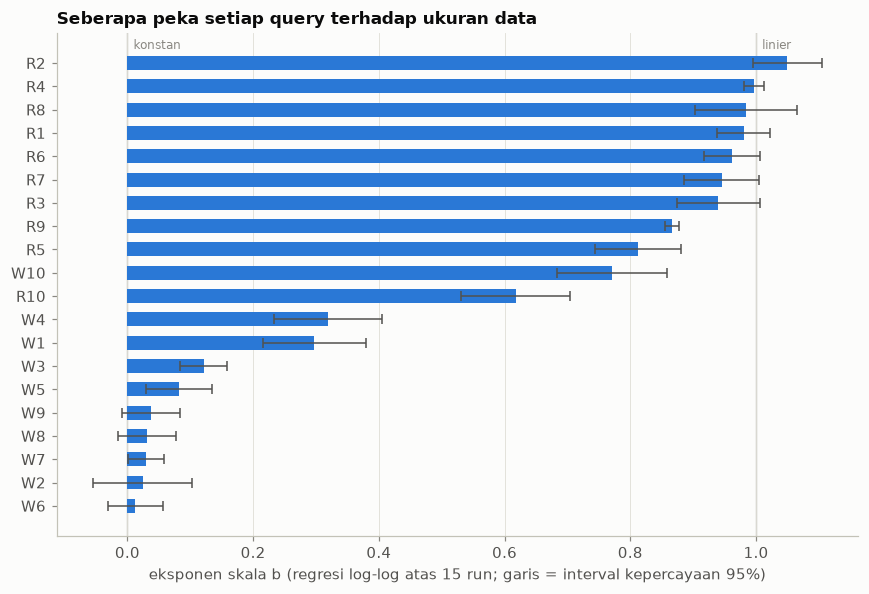

In [37]:
ordered = exponent.sort_values()
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(range(len(ordered)), ordered.values, color=BLUE, height=0.6, zorder=2)
ax.errorbar(ordered.values, range(len(ordered)), xerr=[fits[q]['ci'] for q in ordered.index], fmt='none',
            ecolor=INK_2, elinewidth=1, capsize=3, zorder=3)
ax.set_yticks(range(len(ordered)), labels=ordered.index)
for x, label in [(0, 'konstan'), (1, 'linier')]:
    ax.axvline(x, color=MUTED, lw=0.8, zorder=1)
    ax.annotate(label, (x, len(ordered) - 0.4), xytext=(4, 0), textcoords='offset points', fontsize=8, color=MUTED)
ax.grid(axis='y', visible=False)
ax.set_xlabel('eksponen skala b (regresi log-log atas 15 run; garis = interval kepercayaan 95%)')
ax.set_title('Seberapa peka setiap query terhadap ukuran data')
fig.tight_layout()
plt.show()

In [38]:
no_growth = [q for q in QUERY_ORDER if fits[q]['b'] - fits[q]['ci'] <= 0 <= fits[q]['b'] + fits[q]['ci']]
linear = [q for q in QUERY_ORDER if fits[q]['b'] - fits[q]['ci'] <= 1 <= fits[q]['b'] + fits[q]['ci']]
lines = ['Dibaca secara statistik:']
if no_growth:
    lines.append(f'- **{names(no_growth)}:** interval kepercayaannya mencakup 0. Artinya, dari data ini waktunya '
                 '**tidak terbukti bertambah** saat data membesar 100 kali.')
if linear:
    lines.append(f'- **{names(linear)}:** interval kepercayaannya mencakup 1. Artinya, pertumbuhannya **tidak berbeda '
                 'nyata dari linier**: data 10 kali lebih besar, waktunya juga sekitar 10 kali lebih lama.')
sublinear = [q for q in QUERY_ORDER if q not in no_growth + linear and fits[q]['b'] + fits[q]['ci'] < 1]
superlinear = [q for q in QUERY_ORDER if fits[q]['b'] - fits[q]['ci'] > 1]
if sublinear:
    lines.append(f'- **{names(sublinear)}:** berada di antara keduanya. Waktunya bertambah, tetapi lebih lambat dari '
                 'pertumbuhan data.')
if superlinear:
    lines.append(f'- **{names(superlinear)}:** intervalnya seluruhnya di atas 1. Waktunya bertambah **sedikit lebih '
                 'cepat dari pertumbuhan data**, jadi query ini yang paling perlu diawasi kalau data terus bertambah.')
say('\n'.join(lines))

Dibaca secara statistik:
- **W2, W6, W8 dan W9:** interval kepercayaannya mencakup 0. Artinya, dari data ini waktunya **tidak terbukti bertambah** saat data membesar 100 kali.
- **R1, R2, R3, R4, R6, R7 dan R8:** interval kepercayaannya mencakup 1. Artinya, pertumbuhannya **tidak berbeda nyata dari linier**: data 10 kali lebih besar, waktunya juga sekitar 10 kali lebih lama.
- **R5, R9, R10, W1, W3, W4, W5, W7 dan W10:** berada di antara keduanya. Waktunya bertambah, tetapi lebih lambat dari pertumbuhan data.

### 5.5 Run yang melewati threshold

Bagian ini menghitung semua run dari ke-20 query terhadap tiga threshold di bagian 2: target, zona waspada (≥ 50% target), dan outlier (lebih dari 1,2 kali median query itu di ukuran data yang sama). Tabel pertama menghitung per ukuran data, tabel kedua mendaftar setiap run yang melewati salah satu threshold.

In [39]:
threshold_rows = []
for profile in PROFILES + ['total']:
    frame = bench if profile == 'total' else bench[bench['profile'] == profile]
    total = int(frame['runs'].sum())
    row = {'ukuran data': profile, 'jumlah run': total}
    for label, key in THRESHOLDS:
        count = int(frame[key].sum())
        row[label] = f'{count} ({100 * count / total:.1f}%)'
    threshold_rows.append(row)
display(pd.DataFrame(threshold_rows).set_index('ukuran data'))

flagged = []
for _, r in bench.iterrows():
    for k, t in enumerate(r['times_ms'], 1):
        hits = [name for name, hit in [('target', t > r['slo_ms']),
                                       ('zona waspada', t >= WARN_SHARE * r['slo_ms']),
                                       ('outlier', t > OUTLIER_FACTOR * r['median_ms'])] if hit]
        if hits:
            flagged.append({'ukuran data': str(r['profile']), 'query': str(r['query']), 'run ke-': k,
                            'waktu (ms)': np.round(t, 2), 'median (ms)': np.round(r['median_ms'], 2),
                            'persen dari target': f"{100 * t / r['slo_ms']:.0f}%", 'threshold': ', '.join(hits)})
flagged = pd.DataFrame(flagged, columns=['ukuran data', 'query', 'run ke-', 'waktu (ms)', 'median (ms)',
                                         'persen dari target', 'threshold'])
if flagged.empty:
    say('Tidak ada run yang melewati threshold mana pun.')
else:
    display(flagged.set_index(['ukuran data', 'query', 'run ke-']))

,jumlah run,run > target,run ≥ 50% target,"run > 1,2× median"
ukuran data,,,,
small,100,0 (0.0%),0 (0.0%),5 (5.0%)
medium,100,0 (0.0%),0 (0.0%),2 (2.0%)
large,100,0 (0.0%),10 (10.0%),12 (12.0%)
total,300,0 (0.0%),10 (3.3%),19 (6.3%)


waktu (ms)  median (ms) persen dari target  \
ukuran data query run ke-                                               
small       R2    1             10.92         7.94                 1%   
            R10   1              0.48         0.35                 0%   
            W1    3              7.09         4.50                 4%   
            W2    3              1.53         1.01                 1%   
            W5    1              1.82         1.44                 1%   
medium      W1    1              9.94         7.28                 5%   
            W8    4              1.74         1.37                 1%   
large       R1    1            793.97       605.87                40%   
            R2    1           1041.01      1041.01                52%   
                  2           1030.04      1041.01                52%   
                  3           1051.78      1041.01                53%   
                  4           1031.20      1041.01                52%   
                  5           1240.89      1041.01                62%   
            R3    1           1572.94      1553.20                79%   
                  2           1626.19      1553.20                81%   
                  3           1553.20      1553.20                78%   
                  4           1502.51      1553.20                75%   
                  5           1501.37      1553.20                75%   
            W2    1              1.43         0.96                 1%   
                  3              1.43         0.96                 1%   
            W3    1              2.34         1.73                 1%   
            W5    3              3.24         1.99                 2%   
            W6    3              2.15         1.76                 1%   
            W7    3              4.30         3.48                 2%   
            W8    4              2.30         1.76                 1%   
            W9    3              2.89         2.24                 1%   
                  4              3.50         2.24                 2%   
            W10   1             58.14        45.74                29%   
                  3             56.41        45.74                28%   

                              threshold  
ukuran data query run ke-                
small       R2    1             outlier  
            R10   1             outlier  
            W1    3             outlier  
            W2    3             outlier  
            W5    1             outlier  
medium      W1    1             outlier  
            W8    4             outlier  
large       R1    1             outlier  
            R2    1        zona waspada  
                  2        zona waspada  
                  3        zona waspada  
                  4        zona waspada  
                  5        zona waspada  
            R3    1        zona waspada  
                  2        zona waspada  
                  3        zona waspada  
                  4        zona waspada  
                  5        zona waspada  
            W2    1             outlier  
                  3             outlier  
            W3    1             outlier  
            W5    3             outlier  
            W6    3             outlier  
            W7    3             outlier  
            W8    4             outlier  
            W9    3             outlier  
                  4             outlier  
            W10   1             outlier  
                  3             outlier

In [40]:
n_all = int(bench['runs'].sum())
n_target, n_warn, n_out = (int(bench[key].sum()) for key in ('over_target', 'over_warn', 'outliers'))
lines = [f'- **Target:** {n_target} dari {n_all} run ({pct_id(100 * n_target / n_all)}) melewati target.']
warn_rows = bench[bench['over_warn'] > 0]
lines.append(f'- **Zona waspada:** {n_warn} dari {n_all} run ({pct_id(100 * n_warn / n_all)})' + (
    ', yaitu ' + names(f"{r['query']} di {r['profile']} ({int(r['over_warn'])} dari {int(r['runs'])} run)"
                       for _, r in warn_rows.iterrows()) + '.' if n_warn else '.'))
# Dihitung dari waktu asli, bukan dari tabel yang sudah dibulatkan.
outlier_runs = [(t - r['median_ms'], str(r['query']), str(r['profile']), k, r['median_ms'])
                for _, r in bench.iterrows() for k, t in enumerate(r['times_ms'], 1)
                if t > OUTLIER_FACTOR * r['median_ms']]
if not outlier_runs:
    lines.append(f'- **Outlier:** tidak ada run yang lebih dari {dec(OUTLIER_FACTOR)} kali median-nya.')
else:
    per_profile = {p: sum(run[2] == p for run in outlier_runs) for p in PROFILES}
    fast = sum(run[4] < 10 for run in outlier_runs)
    gap, gap_query, gap_profile, gap_run, _ = max(outlier_runs)
    lines.append(f'- **Outlier:** {n_out} dari {n_all} run ({pct_id(100 * n_out / n_all)}), yaitu '
                 + names(f'{n} di {p}' for p, n in per_profile.items() if n) + '. '
                 f'{fast} di antaranya berasal dari query dengan median di bawah 10 ms. Selisih terbesar dari '
                 f'median adalah {idn(gap)} ms, yaitu {gap_query} di {gap_profile} (run ke-{gap_run}).')
say('\n'.join(lines))

- **Target:** 0 dari 300 run (0,0%) melewati target.
- **Zona waspada:** 10 dari 300 run (3,3%), yaitu R2 di large (5 dari 5 run) dan R3 di large (5 dari 5 run).
- **Outlier:** 19 dari 300 run (6,3%), yaitu 5 di small, 2 di medium dan 12 di large. 16 di antaranya berasal dari query dengan median di bawah 10 ms. Selisih terbesar dari median adalah 188 ms, yaitu R1 di large (run ke-1).

### 5.6 Kenapa ada yang melambat, dan kenapa ada yang tetap cepat?

Saat pemanasan, benchmark juga mencatat *query plan*, yaitu langkah-langkah yang dipilih PostgreSQL untuk menjalankan sebuah query. Dari situ kita bisa melihat penyebabnya. Kolom yang perlu dilihat:
- **Seq scan:** tabel yang terpaksa dibaca dari awal sampai akhir. Ini yang paling penting.
- **Index scan:** berapa kali query bisa langsung melompat ke baris yang dicari.
- **Temp ditulis:** data yang tidak muat di memori kerja (4 MB per operasi), sehingga harus ditulis sementara ke disk.

In [41]:
plans = large[['category', 'seq_scan', 'index_scans', 'workers', 'data_read_mb', 'temp_written_mb', 'median_ms']].copy()
plans.columns = ['kategori', 'seq scan (dibaca seluruhnya)', 'index scan', 'worker paralel', 'data dibaca (MB)',
                 'temp ditulis (MB)', 'median (ms)']
display(plans.loc[[q for q in QUERY_ORDER if q in plans.index]].round(1))

,kategori,seq scan (dibaca seluruhnya),index scan,worker paralel,data dibaca (MB),temp ditulis (MB),median (ms)
query,,,,,,,
R1,Analitik,"driver_assignments, driver_partners, vehicles",0,2,196.8,21.0,605.9
R2,Analitik,"driver_assignments, driver_partners, trips, vehicles",0,2,289.8,127.4,1041.0
R3,Analitik,"driver_assignments, trips, vehicles",0,2,274.7,102.5,1553.2
R4,Analitik,trips,1,2,721.9,0.0,603.9
R5,Analitik,"locations, service_areas, trips",0,2,115.1,0.0,149.4
R6,Analitik,"locations, service_areas, trips",2,2,619.7,73.8,849.4
R7,Analitik,"payments, service_orders",0,2,153.8,133.0,531.2
R8,Analitik,"food_orders, locations, merchant_outlets, payments, service_areas, service_orders",0,2,203.0,19.7,584.2
R9,Analitik,"food_orders, locations, merchant_outlets, service_areas, service_orders",0,1,147.3,0.0,103.3


Bedanya kira-kira seperti mencari satu kata di buku tebal.
- **Tanpa index:** kita harus membaca dari halaman pertama sampai ketemu, jadi makin tebal bukunya, makin lama.
- **Dengan index:** kita cukup membuka daftar indeks di belakang dan langsung menuju halamannya, jadi tebal buku hampir tidak berpengaruh.

In [42]:
analytic_large = large[large['category'] == 'Analitik']
spill = analytic_large.sort_values('temp_written_mb', ascending=False).head(2)
writes_large = large[large['category'] == 'Transaksional']
flat = [q for q in writes_large.index if exponent[q] < 0.2]
slow_growth = [q for q in writes_large.index if 0.2 <= exponent[q] <= 0.5]
growing = [q for q in writes_large.index if exponent[q] > 0.5]
lines = ['Itulah yang terjadi di sini:',
         '- **Query analitik R1–R9 membaca seluruh tabel,** karena tugasnya memang merangkum semua data. Di large, '
         'sebagian juga harus menulis data sementara ke disk karena memori kerjanya tidak cukup, misalnya '
         + names(f"{q} sekitar {v:,.0f} MB".replace(',', '.') for q, v in spill['temp_written_mb'].items()) + '.']
example = ' Contohnya W5 dan W8, yang mencari baris lewat index `driver_assignments(trip_id)` dan `trips(order_id)`.' \
    if {'W5', 'W8'} <= set(flat) else ''
lines.append(f"- **{names(flat)} hampir tidak terpengaruh ukuran data,** karena membaca dan menulis lewat index atau "
             f"primary key. Di large pun paling lama {ms_text(writes_large.loc[flat, 'max_ms'].max())}.{example}")
if slow_growth:
    lines.append(f"- **{names(slow_growth)} tumbuh pelan:** " + names(
        f"{q} sekitar {ms_text(large.loc[q, 'median_ms'])}" for q in slow_growth) + ' di large.')
for q in growing:
    tables = [name for name in large.loc[q, 'seq_scan'].split(', ') if name not in ('service_areas', '-')]
    verdict = 'masih jauh di bawah' if large.loc[q, 'passes'] else 'sudah melewati'
    lines.append(f"- **{q} ikut melambat** (sekitar {ms_text(large.loc[q, 'median_ms'])} di large), karena masih "
                 f"membaca seluruh tabel {names('`' + name + '`' for name in tables)}. Waktu itu {verdict} target "
                 f"{ms_text(large.loc[q, 'slo_ms'])}.")
say('\n'.join(lines))

Itulah yang terjadi di sini:
- **Query analitik R1–R9 membaca seluruh tabel,** karena tugasnya memang merangkum semua data. Di large, sebagian juga harus menulis data sementara ke disk karena memori kerjanya tidak cukup, misalnya R7 sekitar 133 MB dan R2 sekitar 127 MB.
- **W2, W3, W5, W6, W7, W8 dan W9 hampir tidak terpengaruh ukuran data,** karena membaca dan menulis lewat index atau primary key. Di large pun paling lama 4,3 ms. Contohnya W5 dan W8, yang mencari baris lewat index `driver_assignments(trip_id)` dan `trips(order_id)`.
- **W1 dan W4 tumbuh pelan:** W1 sekitar 20 ms dan W4 sekitar 13 ms di large.
- **W10 ikut melambat** (sekitar 46 ms di large), karena masih membaca seluruh tabel `food_orders`. Waktu itu masih jauh di bawah target 200 ms.

### 5.7 Standar deviasi: seberapa konsisten waktunya?

Definisi standar deviasi, koefisien variasi, dan patokannya ada di bagian 2. Tabel berikut menulis setiap hasil sebagai rata-rata ± standar deviasi (koefisien variasi), dalam milidetik.

In [43]:
def short(value):
    return f'{value:,.0f}' if value >= 100 else f'{value:,.1f}' if value >= 10 else f'{value:.2f}'


sd = bench.copy()
sd['hasil'] = [f'{short(m)} ± {short(s)} ({cv:.0f}%)' for m, s, cv in zip(sd['mean_ms'], sd['stdev_ms'], sd['cv_pct'])]
sd_table = sd.pivot_table(index=['category', 'query'], columns='profile', values='hasil', aggfunc='first',
                          observed=True)
sd_table.index.names = ['kategori', 'query']
sd_table.columns = [f'{p} (ms)' for p in sd_table.columns]
display(sd_table)

bands = pd.cut(bench['cv_pct'], [0, 5, 15, float('inf')], labels=['< 5%', '5–15%', '> 15%'], right=False)
count = pd.crosstab([bench['category']], bands).reindex(columns=['< 5%', '5–15%', '> 15%'], fill_value=0)
count.index.name = 'kategori'
count.columns.name = 'koefisien variasi'
display(Markdown('**Jumlah hasil per kelompok koefisien variasi** (20 query × 3 ukuran data = 60 hasil)'))
display(count)

small (ms)        medium (ms)         large (ms)
kategori      query                                                         
Analitik      R1      6.94 ± 0.12 (2%)  53.6 ± 5.42 (10%)   639 ± 88.5 (14%)
              R2     8.62 ± 1.31 (15%)  71.5 ± 6.89 (10%)  1,079 ± 90.9 (8%)
              R3      20.4 ± 0.37 (2%)    276 ± 10.7 (4%)  1,551 ± 52.3 (3%)
              R4      6.13 ± 0.10 (2%)   64.7 ± 4.90 (8%)    605 ± 13.5 (2%)
              R5      3.53 ± 0.14 (4%)   35.9 ± 1.80 (5%)    149 ± 4.95 (3%)
              R6      10.2 ± 0.13 (1%)   123 ± 13.6 (11%)    853 ± 13.8 (2%)
              R7      6.83 ± 0.17 (2%)   88.3 ± 8.13 (9%)    530 ± 7.79 (1%)
              R8      6.24 ± 0.25 (4%)    103 ± 7.99 (8%)    580 ± 13.8 (2%)
              R9      1.90 ± 0.08 (4%)   14.2 ± 0.60 (4%)    103 ± 3.47 (3%)
Operasional   R10    0.38 ± 0.06 (17%)   0.92 ± 0.05 (5%)  6.54 ± 0.65 (10%)
Transaksional W1     4.92 ± 1.23 (25%)  6.92 ± 2.04 (29%)   19.0 ± 1.75 (9%)
              W2     1.01 ± 0.35 (35%)   0.84 ± 0.07 (8%)  1.10 ± 0.30 (27%)
              W3      1.02 ± 0.07 (7%)   1.16 ± 0.02 (2%)  1.81 ± 0.32 (18%)
              W4     3.05 ± 0.39 (13%)   3.68 ± 0.28 (8%)   13.2 ± 0.83 (6%)
              W5     1.53 ± 0.17 (11%)  1.50 ± 0.14 (10%)  2.26 ± 0.55 (24%)
              W6      1.70 ± 0.10 (6%)  1.44 ± 0.14 (10%)  1.81 ± 0.30 (16%)
              W7      3.17 ± 0.26 (8%)  3.18 ± 0.33 (10%)  3.64 ± 0.38 (10%)
              W8     1.52 ± 0.15 (10%)  1.44 ± 0.21 (15%)  1.77 ± 0.33 (19%)
              W9      2.12 ± 0.20 (9%)  2.44 ± 0.30 (12%)  2.57 ± 0.62 (24%)
              W10     1.37 ± 0.06 (4%)   4.75 ± 0.43 (9%)  48.3 ± 8.64 (18%)

**Jumlah hasil per kelompok koefisien variasi** (20 query × 3 ukuran data = 60 hasil)

koefisien variasi,< 5%,5–15%,> 15%
kategori,,,
Analitik,17,9,1
Operasional,0,2,1
Transaksional,2,18,10


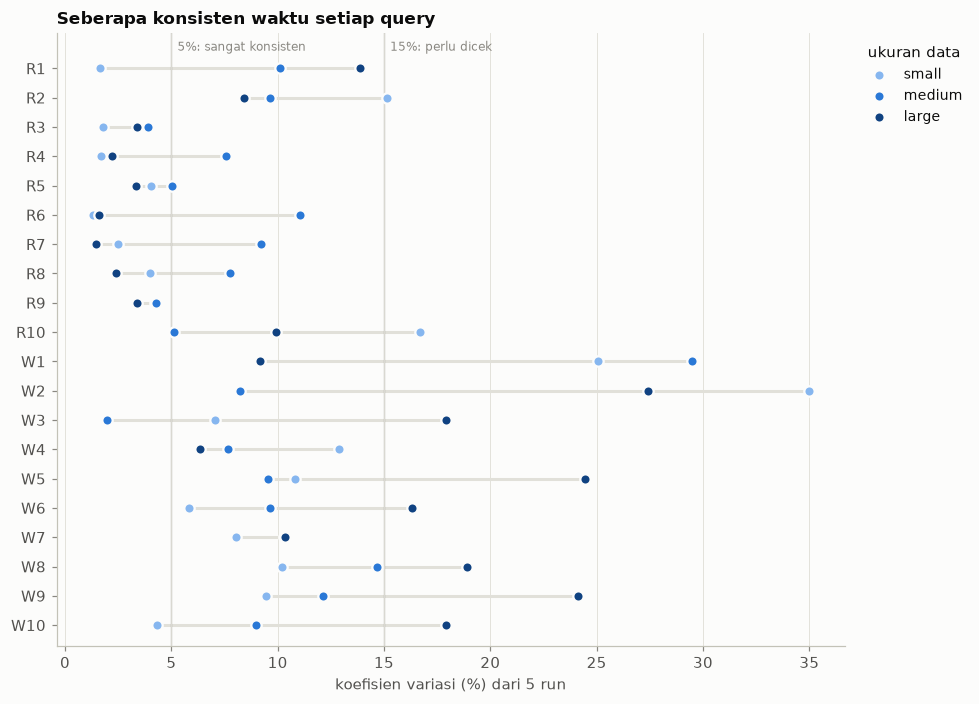

In [44]:
PROFILE_COLORS = {'small': '#86b6ef', 'medium': '#2a78d6', 'large': '#104281'}
order = list(reversed(QUERY_ORDER))
fig, ax = plt.subplots(figsize=(9, 6.5))
for y, query in enumerate(order):
    values = bench[bench['query'] == query].set_index('profile')['cv_pct']
    ax.plot([values.min(), values.max()], [y, y], color=GRID, lw=2, zorder=1)
    for profile in PROFILES:
        ax.scatter(values[profile], y, s=46, color=PROFILE_COLORS[profile], edgecolor=SURFACE, lw=1.5, zorder=3,
                   label=profile if y == 0 else None)
for x, label in [(5, '5%: sangat konsisten'), (15, '15%: perlu dicek')]:
    ax.axvline(x, color=MUTED, lw=0.8, zorder=1)
    ax.annotate(label, (x, len(order) - 0.4), xytext=(4, 0), textcoords='offset points', fontsize=8, color=MUTED)
ax.set_yticks(range(len(order)), labels=order)
ax.set_ylim(-0.7, len(order) + 0.2)
ax.grid(axis='y', visible=False)
ax.set_xlabel('koefisien variasi (%) dari 5 run')
ax.set_title('Seberapa konsisten waktu setiap query')
ax.legend(title='ukuran data', loc='upper left', bbox_to_anchor=(1.01, 1.0))
fig.tight_layout()
plt.show()

Grafik berikut menjelaskan kenapa query yang cepat sering terlihat "goyang".
- **Setiap titik:** satu hasil, yaitu satu query di satu ukuran data. Posisinya adalah rata-rata waktu dan standar deviasinya, dalam milidetik.
- **Dua garis miring:** koefisien variasi 5% dan 15%.
- **Cara membacanya:** titik di atas garis 15% terlihat tidak konsisten kalau diukur dalam persen. Tetapi lihat sumbu tegaknya: untuk query yang cepat, penyimpangannya hanya sepersekian milidetik.

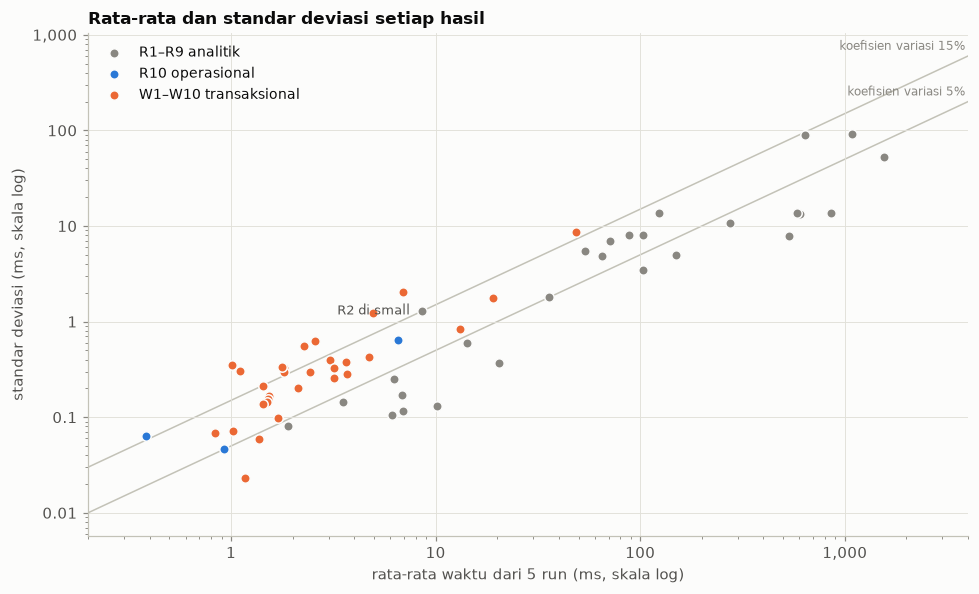

In [45]:
CATEGORY_STYLE = {'Analitik': ('#898781', 'R1–R9 analitik'), 'Operasional': (BLUE, 'R10 operasional'),
                  'Transaksional': (ORANGE, 'W1–W10 transaksional')}
fig, ax = plt.subplots(figsize=(9, 5.5))
xs = [0.2, 4000]
for cv in (5, 15):
    ax.plot(xs, [x * cv / 100 for x in xs], color=AXIS, lw=1, zorder=1)
    ax.annotate(f'koefisien variasi {cv}%', (xs[1], xs[1] * cv / 100), xytext=(-2, 4), textcoords='offset points', ha='right',
                fontsize=8, color=MUTED)
for category_name, (color, label) in CATEGORY_STYLE.items():
    frame = bench[bench['category'] == category_name]
    ax.scatter(frame['mean_ms'], frame['stdev_ms'], s=38, color=color, edgecolor=SURFACE, lw=1, zorder=3, label=label)
for _, row in bench[(bench['cv_pct'] > 15) & (bench['category'] == 'Analitik')].iterrows():
    ax.annotate(f"{row['query']} di {row['profile']}", (row['mean_ms'], row['stdev_ms']), xytext=(-8, 0),
                textcoords='offset points', ha='right', va='center', fontsize=8.5, color=INK_2)
ax.set_xscale('log')
ax.set_yscale('log')
ax.xaxis.set_major_formatter(PLAIN)
ax.yaxis.set_major_formatter(PLAIN)
ax.set_xlim(0.2, 4000)
ax.set_xlabel('rata-rata waktu dari 5 run (ms, skala log)')
ax.set_ylabel('standar deviasi (ms, skala log)')
ax.set_title('Rata-rata dan standar deviasi setiap hasil')
ax.legend(loc='upper left')
fig.tight_layout()
plt.show()

Hasil dengan koefisien variasi di atas 15% kita lihat lebih dekat. Tabel ini menampilkan kelima run-nya, berikut selisih run paling lambat dari median, supaya terlihat seberapa besar penyimpangannya dalam milidetik.

In [46]:
spread = bench[bench['cv_pct'] > 15].copy()
spread['5 run (ms)'] = spread['times_ms'].map(lambda times: ', '.join(short(t) for t in times))
spread['selisih terlambat − median (ms)'] = (spread['max_ms'] - spread['median_ms']).map(short)
spread['koefisien variasi'] = spread['cv_pct'].map('{:.0f}%'.format)
spread = spread[['profile', 'query', 'category', '5 run (ms)', 'selisih terlambat − median (ms)', 'koefisien variasi']]
spread.columns = ['ukuran data', 'query', 'kategori', '5 run (ms)', 'selisih terlambat − median (ms)', 'koefisien variasi']
display(spread.set_index(['ukuran data', 'query']))

kategori                    5 run (ms)  \
ukuran data query                                                
small       R2          Analitik  10.9, 8.42, 7.92, 7.94, 7.90   
            R10      Operasional  0.48, 0.35, 0.35, 0.42, 0.32   
            W1     Transaksional  4.14, 4.50, 7.09, 4.20, 4.67   
            W2     Transaksional  1.01, 0.68, 1.53, 1.13, 0.69   
medium      W1     Transaksional  9.94, 4.81, 7.28, 7.30, 5.26   
large       W2     Transaksional  1.43, 0.96, 1.43, 0.79, 0.92   
            W3     Transaksional  2.34, 1.52, 1.60, 1.84, 1.73   
            W5     Transaksional  2.15, 1.99, 3.24, 1.97, 1.96   
            W6     Transaksional  1.51, 2.10, 2.15, 1.56, 1.76   
            W8     Transaksional  1.46, 1.81, 1.76, 2.30, 1.50   
            W9     Transaksional  2.23, 2.23, 2.89, 3.50, 1.99   
            W10    Transaksional  58.1, 42.7, 56.4, 45.7, 38.4   

                  selisih terlambat − median (ms) koefisien variasi  
ukuran data query                                                    
small       R2                               2.99               15%  
            R10                              0.13               17%  
            W1                               2.59               25%  
            W2                               0.51               35%  
medium      W1                               2.67               29%  
large       W2                               0.47               27%  
            W3                               0.61               18%  
            W5                               1.25               24%  
            W6                               0.39               16%  
            W8                               0.54               19%  
            W9                               1.27               24%  
            W10                              12.4               18%

In [47]:
analytic = bench[bench['category'] == 'Analitik']
fast = bench[bench['mean_ms'] < 10]
max_dev_fast = (fast['max_ms'] - fast['median_ms']).max()
strays = analytic[analytic['cv_pct'] > 15]
lines = ['Secara umum, angkanya bisa dipercaya.',
         f"- **Query analitik konsisten:** {int((analytic['cv_pct'] < 15).sum())} dari {len(analytic)} hasilnya punya "
         f"koefisien variasi di bawah 15%, dan {int((analytic['cv_pct'] < 5).sum())} di antaranya di bawah 5%.",
         '- **Query yang sangat cepat hanya terlihat "goyang" dalam persen.** Untuk query yang rata-ratanya di bawah '
         f'10 ms, run paling lambat paling banyak meleset {ms_text(max_dev_fast)} dari median. Gangguan sekecil apa pun '
         'dari sistem sudah cukup untuk membuatnya terlihat besar dalam persen, padahal kenyataannya tidak terasa.']
if strays.empty:
    lines.append('- **Tidak ada hasil analitik yang benar-benar menyimpang.**')
else:
    lines.append(f'- **Ada {len(strays)} hasil analitik yang menyimpang:**')
    for _, row in strays.iterrows():
        runs_text = names(f'{t:,.0f}'.replace(',', '.') for t in row['times_ms'])
        lines.append(f"  - **{row['query']} di {row['profile']}:** kelima run-nya {runs_text} ms.")
    lines.append('\n  ' + ('Pada hasil ini' if len(strays) == 1 else 'Pada hasil-hasil ini')
                 + ', sebagian besar run-nya berdekatan, dan hanya satu atau dua run yang jauh lebih lambat. Pola seperti '
                 'ini biasanya datang dari aktivitas lain di mesin pada saat itu, bukan dari query-nya.')
lines.append('\nInilah alasan kita memakai median untuk melihat tren, dan run paling lambat untuk mengecek target. '
             'Dengan begitu, penyimpangan seperti ini tidak sampai membuat kesimpulan kita terlalu optimis.')
say('\n'.join(lines))

Secara umum, angkanya bisa dipercaya.
- **Query analitik konsisten:** 26 dari 27 hasilnya punya koefisien variasi di bawah 15%, dan 17 di antaranya di bawah 5%.
- **Query yang sangat cepat hanya terlihat "goyang" dalam persen.** Untuk query yang rata-ratanya di bawah 10 ms, run paling lambat paling banyak meleset 3,0 ms dari median. Gangguan sekecil apa pun dari sistem sudah cukup untuk membuatnya terlihat besar dalam persen, padahal kenyataannya tidak terasa.
- **Ada 1 hasil analitik yang menyimpang:**
  - **R2 di small:** kelima run-nya 11, 8, 8, 8 dan 8 ms.

  Pada hasil ini, sebagian besar run-nya berdekatan, dan hanya satu atau dua run yang jauh lebih lambat. Pola seperti ini biasanya datang dari aktivitas lain di mesin pada saat itu, bukan dari query-nya.

Inilah alasan kita memakai median untuk melihat tren, dan run paling lambat untuk mengecek target. Dengan begitu, penyimpangan seperti ini tidak sampai membuat kesimpulan kita terlalu optimis.

### 5.8 Error rate

Error rate adalah persentase eksekusi yang gagal. Kita bisa menghitungnya dengan pasti karena benchmark diatur untuk langsung berhenti begitu ada satu statement yang error, tanpa menyimpan hasil apa pun. Jadi hasil yang lengkap, yaitu lima run untuk setiap query, berarti semua eksekusinya berhasil.

In [48]:
complete = bench['times_ms'].map(len) == bench['profile'].map(TIMED_RUNS)
errors = bench.assign(failed=~complete).groupby('profile', observed=True).agg(
    query=('query', 'count'), gagal=('failed', 'sum'))
errors['eksekusi per query'] = [EXECUTIONS[p] for p in errors.index]
errors['total eksekusi'] = errors['query'] * errors['eksekusi per query']
errors['eksekusi gagal'] = errors['gagal'] * errors['eksekusi per query']
errors['error rate'] = (100 * errors['eksekusi gagal'] / errors['total eksekusi']).map('{:.0f}%'.format)
table = errors[['query', 'eksekusi per query', 'total eksekusi', 'eksekusi gagal', 'error rate']].astype(str)
table.index = table.index.astype(str)
total_runs, total_failed = errors['total eksekusi'].sum(), errors['eksekusi gagal'].sum()
table.loc['total'] = [str(errors['query'].sum()), '', str(total_runs), str(total_failed),
                      f'{100 * total_failed / total_runs:.0f}%']
table.index.name = 'ukuran data'
display(table)

,query,eksekusi per query,total eksekusi,eksekusi gagal,error rate
ukuran data,,,,,
small,20,6,120,0,0%
medium,20,6,120,0,0%
large,20,6,120,0,0%
total,60,,360,0,0%


In [49]:
say(f"Hasilnya: dari {total_runs} eksekusi, **{total_failed} gagal**, jadi error rate-nya "
    f"**{100 * total_failed / total_runs:.0f}%**.")

Hasilnya: dari 360 eksekusi, **0 gagal**, jadi error rate-nya **0%**.

Tapi tidak error belum tentu berhasil. Sebuah write bisa saja berjalan tanpa error tetapi tidak mengubah apa-apa, misalnya `UPDATE` yang tidak menemukan baris yang dicari. Karena itu, kita cek juga berapa baris yang diubah setiap write, di setiap run dan setiap ukuran data.

In [50]:
writes = bench[bench['category'] == 'Transaksional']
changed = writes.pivot_table(index='query', columns='profile', values='rows', observed=True)[PROFILES].astype(int)
changed.columns = [f'baris diubah ({p})' for p in PROFILES]
same_runs = writes.groupby('query', observed=True)['rows_per_run'].agg(lambda runs: all(len(set(r)) == 1 for r in runs))
changed['sama di semua run'] = same_runs.map({True: 'ya', False: 'tidak'})
changed['sama di semua ukuran data'] = (changed.iloc[:, :3].nunique(axis=1) == 1).map({True: 'ya', False: 'tidak'})
display(changed)

,baris diubah (small),baris diubah (medium),baris diubah (large),sama di semua run,sama di semua ukuran data
query,,,,,
W1,4,4,4,ya,ya
W2,1,1,1,ya,ya
W3,3,3,3,ya,ya
W4,6,6,6,ya,ya
W5,3,3,3,ya,ya
W6,6,6,6,ya,ya
W7,8,8,8,ya,ya
W8,3,3,3,ya,ya
W9,7,7,7,ya,ya


In [51]:
mismatch = changed[(changed['sama di semua run'] != 'ya') | (changed['sama di semua ukuran data'] != 'ya')]
say('Jumlah baris yang diubah sama persis di setiap run dan setiap ukuran data. Artinya, setiap write benar-benar '
    'mengerjakan hal yang sama setiap kali dijalankan.' if mismatch.empty else
    'Ada write yang jumlah baris diubahnya berbeda: ' + names(mismatch.index) + '. Ini perlu diperiksa.')

Jumlah baris yang diubah sama persis di setiap run dan setiap ukuran data. Artinya, setiap write benar-benar mengerjakan hal yang sama setiap kali dijalankan.

## 6. Kesimpulan

Grafik ini merangkum hasil di ukuran data terbesar. Setiap batang menunjukkan berapa persen dari target yang sudah dipakai oleh run paling lambat setiap query. Semakin panjang batangnya, semakin dekat query itu ke batasnya.

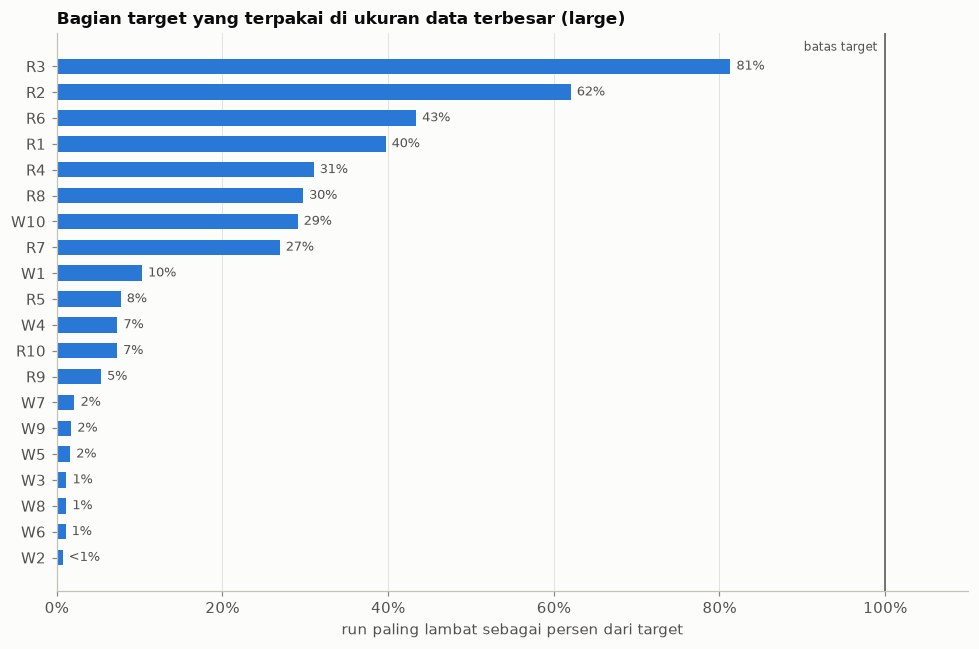

In [52]:
summary_large = bench[bench['profile'] == 'large'].assign(
    pct=lambda f: 100 * f['max_ms'] / f['slo_ms']).sort_values('pct')
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(summary_large['query'].astype(str), summary_large['pct'], color=BLUE, height=0.6, zorder=2)
for y, pct in enumerate(summary_large['pct']):
    label = '<1%' if pct < 1 else f'{pct:.0f}%'
    ax.annotate(label, (pct, y), xytext=(4, 0), textcoords='offset points', va='center', fontsize=8.5, color=INK_2)
ax.axvline(100, color=INK_2, lw=1, zorder=3)
ax.annotate('batas target', (100, len(summary_large) - 0.4), xytext=(-5, 0), textcoords='offset points',
            ha='right', fontsize=8, color=INK_2)
ax.set_xlim(0, 110)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v:.0f}%'))
ax.grid(axis='y', visible=False)
ax.set_xlabel('run paling lambat sebagai persen dari target')
ax.set_title('Bagian target yang terpakai di ukuran data terbesar (large)')
fig.tight_layout()
plt.show()

In [53]:
closest_row = bench.loc[(bench['max_ms'] / bench['slo_ms']).idxmax()]
closest_query = str(closest_row['query'])
slowest_write = writes_large['max_ms'].idxmax()
failed_all = bench[~bench['passes']]
lines = ['- **Semua query lulus target** di ketiga ukuran data.' if failed_all.empty else
         f'- **{len(failed_all)} hasil tidak lulus target:** '
         + names(f"{r['query']} di {r['profile']}" for _, r in failed_all.iterrows()) + '.',
         ('- **Query analitik paling peka terhadap ukuran data.** ' + (
             f"Yang paling berat adalah {closest_query}: run paling lambatnya {ms_text(closest_row['max_ms'])}, "
             f"melewati batas {ms_text(closest_row['slo_ms'])} di {closest_row['profile']}."
             if closest_row['max_ms'] > closest_row['slo_ms'] else
             f"Yang paling dekat ke batas adalah {closest_query}, dengan {ms_text(closest_row['max_ms'])} dari batas "
             f"{ms_text(closest_row['slo_ms'])} di {closest_row['profile']}.")),
         f"- **Query yang memakai index tetap cepat,** berapa pun ukuran datanya. R10 butuh {ms_text(large.loc['R10', 'max_ms'])} "
         f"di large, dan write paling lambat ({slowest_write}) hanya {ms_text(writes_large.loc[slowest_write, 'max_ms'])} "
         f"dari target {ms_text(writes_large.loc[slowest_write, 'slo_ms'])}.",
         f"- **Hasilnya bisa dipercaya:** konsisten dari run ke run, dan "
         + ('tanpa error.' if total_failed == 0 else f'{total_failed} eksekusi gagal.'),
         f"- **Threshold:** dari {int(bench['runs'].sum())} run, {int(bench['over_target'].sum())} melewati target, "
         f"{int(bench['over_warn'].sum())} ada di zona waspada, dan {int(bench['outliers'].sum())} termasuk outlier.",
         '',
         '*Uji ini memakai satu pengguna di satu mesin. Target waktu dan threshold di atas adalah patokan yang kita '
         'tentukan sendiri (bagian 1 dan 2).*']
say('\n'.join(lines))

- **Semua query lulus target** di ketiga ukuran data.
- **Query analitik paling peka terhadap ukuran data.** Yang paling dekat ke batas adalah R3, dengan 1,6 detik dari batas 2 detik di large.
- **Query yang memakai index tetap cepat,** berapa pun ukuran datanya. R10 butuh 7,3 ms di large, dan write paling lambat (W10) hanya 58 ms dari target 200 ms.
- **Hasilnya bisa dipercaya:** konsisten dari run ke run, dan tanpa error.
- **Threshold:** dari 300 run, 0 melewati target, 10 ada di zona waspada, dan 19 termasuk outlier.

*Uji ini memakai satu pengguna di satu mesin. Target waktu dan threshold di atas adalah patokan yang kita tentukan sendiri (bagian 1 dan 2).*

### Cara menjalankan ulang

1. Jalankan `scripts/benchmark.py` untuk ketiga ukuran data (lihat `scripts/README.md`).
2. Jalankan `uv sync --group notebook`.
3. Buka notebook ini di VS Code dengan kernel `.venv`, atau jalankan dari root repo:

```bash
uv run --group notebook jupyter nbconvert --to notebook --execute --inplace notebook/volume_test.ipynb
```

Notebook selalu membaca hasil terbaru di `results/`.